# Model verification

## Part 1 - Representative weeks

**Goal.** Check that a reduced time set (4 or 8 representative weeks, 3 h step) reproduces the statistical behaviour of the full year for every time-varying input.

**Steps in this notebook**
1. Read the full-year (52 weeks x 168 h = 8736 h) input profiles from `base/data` and aggregate each to one system-level series.
2. Plot them over the year.
3. Define the pass test: weighted load-duration curves of the selected weeks against the full year.
4. Pick 4 weeks, one per season (winter, spring, summer, autumn), by searching all combinations for the best result in that test.
5. Compare with typical weeks per season and with the weeks currently in the model.
6. Repeat the selection for 8 weeks (2 per season) and quantify what the extra 4 weeks buy in accuracy.
7. Repeat the comparison with the model simulating every 3rd hour.
8. Compare keeping all hours of each week with keeping only three days (2 weekdays and 1 weekend day), both every 3rd hour.

**Things to know about the inputs**
- The profile files hold one fixed *weather year* (S01-S52, T001-T168), not calendar 2025. The model year (2025) only matters for quantities that are scaled by year: here the EV fleet.
- `EV_BEV_available` is set to 0 for 2025 in the input file, so a 2025 EV demand would be flat zero. The EV series therefore uses the fleet of `EV_YEAR` (2030, the first year with profile data).
- Hydro is only available as one value per week (no hourly shape), so it is plotted as steps. Both hydro series are **not part of the load-duration test** (a duration curve over 4 weekly values says little about inflow); they are shown in the yearly plots only. Hydrogen (flat) is not tested either.
- The EV return profile has one outlier hour (S52.T168, about 12x the next-highest hour). It is capped in the analysis (see `load_profiles`); worth checking in the input data.
- Hydrogen demand has no variation in the model (`HYDROGEN_DH2_VAR_T = 1`). It is shown for completeness and excluded from week selection.

In [56]:
import io
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- settings ---------------------------------------------------------------
# Paths relative to the Balmorel repository (the folder holding base/data), so the notebook runs on Windows and on the HPC
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base" / "data").is_dir())
BASE_DATA = ROOT / "base" / "data"
CACHE = ROOT / "Data_python" / "verification_profiles.pkl"   # aggregated series; delete to re-read the .inc files
YEAR = 2025        # model year of the study (the profiles themselves are one fixed weather year)
EV_YEAR = 2030     # EV fleet and profile year (the 2025 fleet is overridden to 0 in EV_BEV_available.inc)
N_WEEKS, N_HOURS = 52, 168

# Seasons by week of the input year, used to choose the weeks (weeks per season: 12 / 13 / 14 / 13 = 52)
SEASONS = {
    "Winter": list(range(49, 53)) + list(range(1, 9)),
    "Spring": list(range(9, 22)),
    "Summer": list(range(22, 36)),
    "Autumn": list(range(36, 49)),
}
CURRENT_4 = [2, 15, 28, 41]          # weeks currently in base_dc_4 / base_no_dc_4 (S.inc)

# Categorical colours, fixed per series (same palette as the other notebooks)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#7a7a7a", "#00a3b8"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.88", "grid.linewidth": 0.6, "font.size": 9})

### 1. Parsing helpers

The `.inc` files are GAMS tables. The big hourly ones (`S01.T001 value value ...`) are read with pandas after locating the first data row; the small weekly hydro tables are parsed line by line.

In [57]:
# row labels look like 'S01.T001', 'PII.S01.T001' or '2030 . S01 . T001'
LABEL = re.compile(r"^\s*(?:(?P<key>[^.\s]+)\s*\.\s*)?S(?P<week>\d+)\s*\.\s*T(?P<hour>\d+)\b")


def read_hourly_table(path):
    """Read a GAMS table with rows '[key.]Sxx.Tyyy' and one column per element.
    Returns a DataFrame indexed by (key, week, hour); key is '' when the label has no prefix."""
    lines = Path(path).read_text(encoding="latin1").splitlines()
    # a file can hold several blocks of rows (e.g. DE_VAR_T: one block per user), each under its own header line
    blocks, header = [], None
    for i, l in enumerate(lines):
        m = LABEL.match(l)
        if m is None:
            if l.strip() and not l.lstrip().startswith("*") and not l.lstrip().startswith(";"):
                header = l
            continue
        if not blocks or blocks[-1]["end"] != i - 1:         # first row of a new block
            blocks.append({"header": header, "rows": [], "end": i})
        blocks[-1]["rows"].append((m, l[m.end():]))           # row text without its label
        blocks[-1]["end"] = i
    parts = []
    for b in blocks:
        cols = [c for c in b["header"].split() if c != "+"]
        values = pd.read_csv(io.StringIO("\n".join(t for _, t in b["rows"])), header=None, sep=r"\s+")
        assert values.shape[1] == len(cols), \
            f"{Path(path).name}: {values.shape[1]} values per row but {len(cols)} columns in the header"
        values = values.set_axis(cols, axis=1).astype("float32")
        values.index = pd.MultiIndex.from_tuples(
            [(m["key"] or "", int(m["week"]), int(m["hour"])) for m, _ in b["rows"]], names=["key", "week", "hour"])
        parts.append(values)
    return pd.concat(parts).sort_index()


def read_plain_table(path, name):
    """Read the GAMS table block 'TABLE name(...)': header line = columns, first token of each row = index."""
    lines = Path(path).read_text(encoding="latin1").splitlines()
    start = next(i for i, l in enumerate(lines) if re.match(rf"^\s*TABLE\s+{name}\b", l, re.I))
    rows, cols = [], None
    for l in lines[start + 1:]:
        s = l.strip()
        if s.startswith(";"):
            break
        if not s or s.startswith("*"):
            continue
        if cols is None:
            cols = s.split()
            continue
        rows.append(s.split())
    assert all(len(r) == len(cols) + 1 for r in rows), f"{name}: rows and header differ in length"
    return pd.DataFrame([[float(v) for v in r[1:]] for r in rows], index=[r[0] for r in rows], columns=cols)


def per_hour(df):
    """Sum a (key, week, hour) table over the keys, giving (week, hour) x columns."""
    return df.groupby(level=["week", "hour"]).sum()

### 2. One system-level series per input

| Series | Source | Aggregation (assumption) |
|---|---|---|
| Solar | `SOLE_VAR_T.inc` | mean capacity factor over all solar areas |
| Wind onshore / offshore | `WND_VAR_T_ON1/ON2/Existing.inc`, `WND_VAR_T_OFF.inc` | mean capacity factor over all areas; columns with `OFF` in the name are offshore |
| Hydro reservoir inflow | `WTRRSVAR_S.inc` | sum over areas, weekly values |
| Hydro run-of-river | `WTRRRVAR_T.inc` (`WTRRRVAR_S`) | sum over areas, weekly values |
| Electricity demand | `DE_VAR_T.inc` | sum over regions and users (profile values are on the scale of the regional demand) |
| Heat demand | `DH_VAR_T.inc` | sum over district-heating areas |
| Hydrogen demand | `HYDROGEN_DH2_VAR_T.inc` | constant 1 |
| EV demand | `EV_BEV_return_profile1.inc` x `EV_BEV_available.inc` | plugged-in share x fleet, summed over regions (profile 1; check `EV_profile` in the run options) |

The mean over areas ignores installed capacity. It is a first proxy for the *shape*; weighting by capacity can be added later.

In [58]:
def load_profiles():
    series, units = {}, {}

    # --- solar and wind: capacity factors, mean over areas
    solar = read_hourly_table(BASE_DATA / "SOLE_VAR_T.inc").droplevel("key")
    idx = solar.index
    series["Solar"], units["Solar"] = solar.mean(axis=1), "capacity factor"

    wind = pd.concat([read_hourly_table(BASE_DATA / f).droplevel("key")
                      for f in ["WND_VAR_T_OFF.inc", "WND_VAR_T_ON1.inc", "WND_VAR_T_ON2.inc", "WND_VAR_T_Existing.inc"]], axis=1)
    is_off = wind.columns.str.contains("OFF")
    print(f"wind areas: {int(is_off.sum())} offshore, {int((~is_off).sum())} onshore")
    series["Wind offshore"], units["Wind offshore"] = wind.loc[:, is_off].mean(axis=1), "capacity factor"
    series["Wind onshore"], units["Wind onshore"] = wind.loc[:, ~is_off].mean(axis=1), "capacity factor"

    # --- hydro: one value per week, repeated over the 168 hours of the week
    reservoir = read_plain_table(BASE_DATA / "WTRRSVAR_S.inc", "WTRRSVAR_S").sum().sort_index()     # S01..S52
    ror = read_plain_table(BASE_DATA / "WTRRRVAR_T.inc", "WTRRRVAR_S").sum(axis=1).sort_index()    # S01..S52
    for name, weekly, unit in [("Hydro reservoir inflow", reservoir, "GWh/week"),
                               ("Hydro run-of-river", ror, "weekly generation index")]:
        assert len(weekly) == N_WEEKS, f"{name}: {len(weekly)} weeks"
        series[name], units[name] = pd.Series(np.repeat(weekly.values, N_HOURS), index=idx), unit

    # --- demands
    series["Electricity demand"], units["Electricity demand"] = \
        per_hour(read_hourly_table(BASE_DATA / "DE_VAR_T.inc")).sum(axis=1), "MW (sum of profiles)"
    series["Heat demand"], units["Heat demand"] = \
        read_hourly_table(BASE_DATA / "DH_VAR_T.inc").droplevel("key").sum(axis=1), "MW (sum of profiles)"
    series["Hydrogen demand"], units["Hydrogen demand"] = pd.Series(1.0, index=idx), "relative (flat)"

    # --- EV: plugged-in share (return profile) x fleet
    fleet = read_plain_table(BASE_DATA / "EV_BEV_available.inc", "EV_BEV_available").loc[str(EV_YEAR)]
    ev = read_hourly_table(BASE_DATA / "EV_BEV_return_profile1.inc").xs(str(EV_YEAR), level="key")
    common = fleet.index.intersection(ev.columns)
    print(f"EV: {len(common)} regions with fleet and profile; regions with fleet but no profile: "
          f"{int((fleet.drop(common) > 0).sum())}")
    ev_total = (ev[common] * fleet[common]).sum(axis=1)
    # S52.T168 holds a single-hour outlier (about 12x the next-highest hour): cap it at the next-highest value so it
    # does not dominate the plots, the weekly maximum and the duration curve. Remove this line to see the raw data.
    spike = ev_total.idxmax()
    print(f"EV outlier at S{spike[0]:02d}.T{spike[1]:03d}: {ev_total[spike]:.3g} -> capped at {ev_total.drop(spike).max():.3g}")
    ev_total = ev_total.clip(upper=ev_total.drop(spike).max())
    series["EV demand"], units["EV demand"] = ev_total, "vehicles plugging in (x return share)"

    out = pd.DataFrame(series)
    assert out.index.equals(idx), "series are not on the same (week, hour) index"
    return out, units


try:
    hourly, units = pd.read_pickle(CACHE)
except Exception as exc:     # no cache yet, or written by another pandas version (e.g. pandas 3 on Windows vs 2.2 on the HPC)
    if CACHE.exists():
        print(f"cache not readable here ({type(exc).__name__}), re-reading the .inc files")
    hourly, units = load_profiles()
    pd.to_pickle((hourly, units), CACHE)

assert hourly.shape == (N_WEEKS * N_HOURS, 9), hourly.shape
assert not hourly.isna().any().any(), "NaN in profiles"
SERIES = list(hourly.columns)
COLOR = {name: PAL[i] for i, name in enumerate(SERIES)}      # colour follows the series, never its rank
VARYING = [s for s in SERIES if s != "Hydrogen demand"]
NOT_TESTED = ["Hydro reservoir inflow", "Hydro run-of-river", "Hydrogen demand"]       # weekly hydro values; flat H2
TESTED = [s for s in SERIES if s not in NOT_TESTED]                                    # inputs in the load-duration test

summary = pd.DataFrame({"unit": pd.Series(units), "mean": hourly.mean(), "min": hourly.min(), "max": hourly.max(),
                        "max / mean": hourly.max() / hourly.mean()})
display(summary.style.format({"mean": "{:,.3g}", "min": "{:,.3g}", "max": "{:,.3g}", "max / mean": "{:.2f}"}))

,unit,mean,min,max,max / mean
Solar,capacity factor,0.177,0,0.83,4.70
Wind offshore,capacity factor,0.416,0.0424,0.791,1.90
Wind onshore,capacity factor,0.343,0.0584,0.715,2.08
Hydro reservoir inflow,GWh/week,5.82e+04,1.07e+04,2.46e+05,4.23
Hydro run-of-river,weekly generation index,7.55e+03,4.6e+03,1.29e+04,1.71
Electricity demand,MW (sum of profiles),3.5e+05,2.26e+05,5.09e+05,1.46
Heat demand,MW (sum of profiles),5.6e+06,1.05e+06,1.77e+07,3.16
Hydrogen demand,relative (flat),1,1,1,1.00
EV demand,vehicles plugging in (x return share),4.03e+05,0,1.68e+06,4.17


### 3. Inputs over the full year

Thin grey = hourly values, coloured line = weekly mean. Shaded bands mark winter and summer (spring and autumn lie between). The x-axis is the week of the input year; week *w* spans x = *w* to *w* + 1.

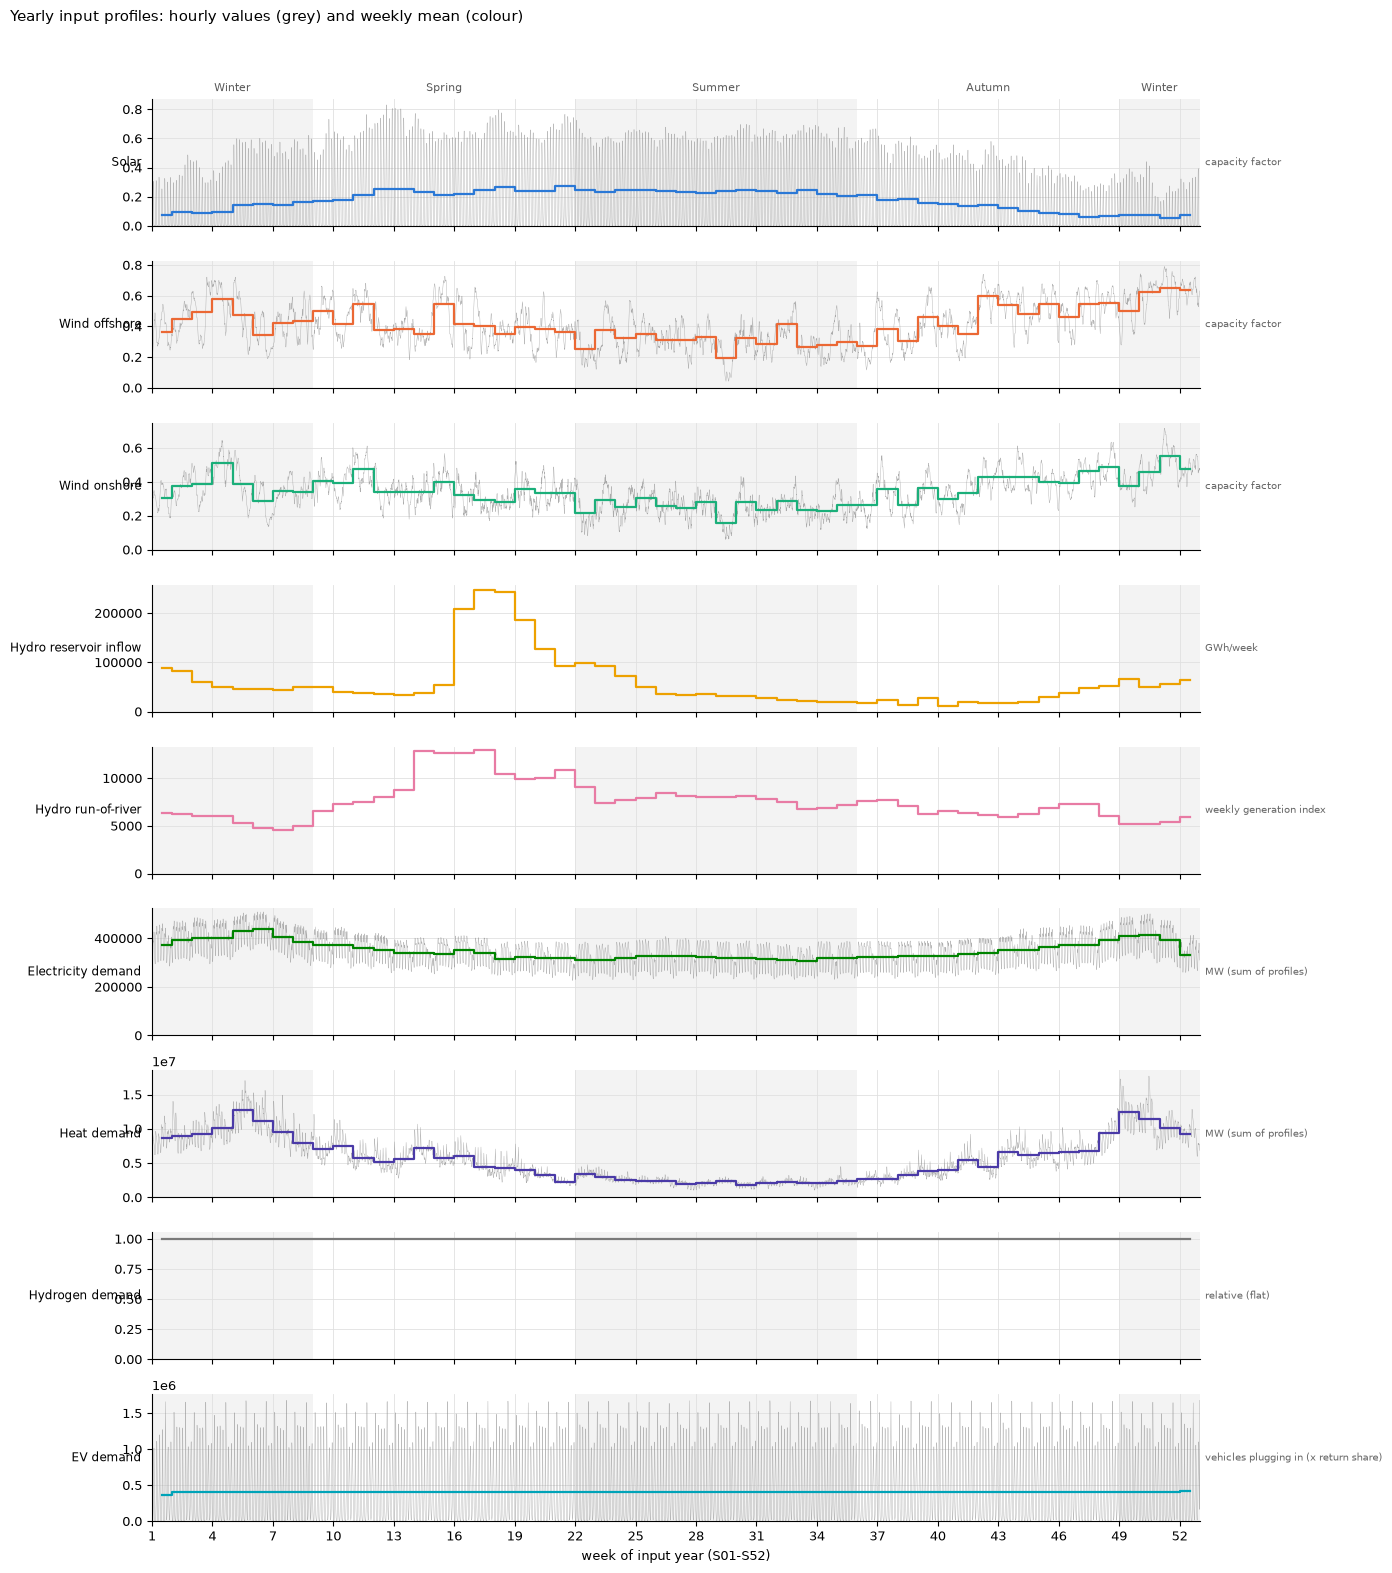

In [59]:
hours_axis = np.arange(len(hourly)) / N_HOURS + 1          # week of year, fractional (week w covers [w, w+1))
weekly_mean = hourly.groupby(level="week").mean()
SEASON_SPANS = {"Winter": [(1, 9), (49, 53)], "Spring": [(9, 22)], "Summer": [(22, 36)], "Autumn": [(36, 49)]}


def shade_seasons(ax, label=False):
    for season in ["Winter", "Summer"]:
        for lo, hi in SEASON_SPANS[season]:
            ax.axvspan(lo, hi, color="0.5", alpha=0.09, lw=0)
    if label:
        for season, spans in SEASON_SPANS.items():
            for lo, hi in spans:
                ax.text((lo + hi) / 2, 1.04, season, transform=ax.get_xaxis_transform(),
                        ha="center", va="bottom", fontsize=8, color="0.35")


def plot_year(selected=None, title=None):
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(14, 1.75 * len(SERIES)), sharex=True)
    for ax, name in zip(axes, SERIES):
        shade_seasons(ax, label=(name == SERIES[0]))
        if not name.startswith("Hydro"):
            ax.plot(hours_axis, hourly[name].values, color="0.55", lw=0.3, alpha=0.7)
        ax.step(np.arange(1, N_WEEKS + 1) + 0.5, weekly_mean[name].values, where="mid", color=COLOR[name], lw=1.6)
        for w in (selected or []):
            ax.axvspan(w, w + 1, color="k", alpha=0.22, lw=0)
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8.5)
        ax.yaxis.set_label_coords(-0.01, 0.5)
        ax.text(1.005, 0.5, units[name], transform=ax.transAxes, fontsize=7, color="0.4", va="center")
        ax.set_ylim(bottom=0)
    axes[-1].set_xlim(1, N_WEEKS + 1)
    axes[-1].set_xticks(range(1, 53, 3))
    axes[-1].set_xlabel("week of input year (S01-S52)")
    if title is None:
        title = "Yearly input profiles: hourly values (grey) and weekly mean (colour)"
        if selected:
            title += " - selected weeks " + ", ".join(f"S{w:02d}" for w in sorted(selected))
    fig.suptitle(title, x=0.01, y=0.995, ha="left", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.975))           # leave room above the season labels for the title
    return fig


plot_year()
plt.show()

### 4. Pass test - load-duration curves

For every input the **weighted** load-duration curve (LDC) of the selected weeks is compared with the LDC of the full year. Hydro (weekly values only) and hydrogen (flat) are not tested. Weights follow the model's convention: `WEIGHT_S` in `WEIGHT_S.inc` is 168 for every season, so all selected weeks count equally (with 4 weeks each represents 13 weeks).

**Rescaling.** The model divides every demand and generation profile by its own sum over the simulated hours, so the annual energy of each input is fixed by the input data (`timeseries_scaling = usedtimesteps_timseries_scaling`, see `Balmorelbb4.inc`). The level of the selected weeks therefore does not matter, only the *shape*. The test does the same: the selected values are multiplied by (full-year mean / selected mean) before the curves are compared. The *level offset* (selected mean / full-year mean - 1) is shown for information only and is not tested. The model rescales every region and area separately; the test rescales the system-wide series, which is an approximation.

| Metric | Definition | Proposed threshold |
|---|---|---|
| LDC error | RMS difference between the two LDCs over all exceedance percentiles, divided by the full-year mean | below 5 % |
| Tail error | difference at the 5 % and 95 % exceedance points, divided by the full-year mean | within 10 % each |

The absolute maximum and minimum are shown but not tested: a few weeks cannot be expected to contain the single most extreme hour. Peak and residual-load adequacy are better tested with the stress scenarios later in this notebook.
The thresholds are a starting proposal - what matters for the model is whether results change, which Part 2 checks by comparing 4 vs 8 weeks.

In [60]:
Q = np.linspace(0.5, 99.5, 199)                    # exceedance percentiles of the LDC (the single max/min hour is not tested)
THRESH = {"ldc": 0.05, "tail": 0.10}


def model_week_weights(weeks, scenario_dir=None):
    """Weeks represented by each selected week, from the model's WEIGHT_S (relative weights, normalised to 52 weeks).
    Reads WEIGHT_S.inc of the scenario if it has one, otherwise base/data (WEIGHT_S(SSS)=168: equal weights)."""
    path = Path(scenario_dir or "") / "WEIGHT_S.inc"
    path = path if scenario_dir and path.exists() else BASE_DATA / "WEIGHT_S.inc"
    text = path.read_text(encoding="latin1")
    constant = re.findall(r"^\s*WEIGHT_S\(SSS\)\s*=\s*([\d.]+)\s*;", text, re.M)
    assert len(constant) == 1 and len(re.findall(r"^\s*WEIGHT_S\(", text, re.M)) == 1, \
        f"{path.name} is not a single constant weight - read the per-season weights here"
    return {w: N_WEEKS / len(weeks) for w in weeks}      # equal WEIGHT_S for all seasons


def ldc(values, weights):
    """Value exceeded during q % of the (weighted) time, for q in Q."""
    order = np.argsort(-values)
    cum = np.cumsum(weights[order]) / weights.sum()
    return np.interp(Q / 100, cum, values[order])


EV_SERIES = "EV demand"      # the model averages EV profiles over the hours around each simulated hour
_REDUCED = {}


def simulated_hours(step, phase):
    """1-based hours of the week the model simulates: step 3, phase 0 -> 1, 4, 7, ..., 166 (T001, T004, ...)."""
    return np.arange(phase + 1, N_HOURS + 1, step)


def reduce_to_hours(hourly, hours):
    """Input values as the model sees them when it simulates only `hours` (1-based, the same in every week).
    All inputs are taken at the simulated hours (the model picks a subset of T and does not average them).
    EV demand is the exception: EV_ipardecdef.inc replaces the profile at each simulated hour by its mean over the
    hours around it (from halfway to the previous simulated hour to halfway to the next one)."""
    t = np.asarray(sorted(hours))
    if len(t) == N_HOURS:
        return hourly
    key = tuple(t)
    if key not in _REDUCED:
        idx = (np.arange(N_WEEKS)[:, None] * N_HOURS + (t - 1)[None, :]).ravel()
        out = hourly.iloc[idx].copy()
        half = t[:-1] + (t[1:] - t[:-1] - 1) // 2                    # last hour of each window except the final one
        lo, hi = np.r_[1, half + 1], np.r_[half, N_HOURS]            # window of every simulated hour (1-based)
        ev = hourly[EV_SERIES].values.reshape(N_WEEKS, N_HOURS)
        cum = np.concatenate([np.zeros((N_WEEKS, 1)), np.cumsum(ev, axis=1)], axis=1)
        out[EV_SERIES] = ((cum[:, hi] - cum[:, lo - 1]) / (hi - lo + 1)).ravel()
        _REDUCED[key] = out
    return _REDUCED[key]


def reduce_to_step(hourly, step=1, phase=0):
    return reduce_to_hours(hourly, simulated_hours(step, phase))


def compare_ldc(hourly, weights_by_week, step=1, phase=0, like_for_like=False, hours=None):
    """Weighted selection vs full year. Returns (metrics table, {series: (ldc_full, ldc_sel)}).
    The selected values are rescaled to the full-year mean (as the model does) before the curves are compared.
    step / phase: every `step`-th hour of the week, starting at hour `phase` + 1 (step=3, phase=0: T001, T004, ...).
    hours: simulate only these hours of each selected week instead (e.g. three days); step / phase then only define
    the full-year reference used when like_for_like is True.
    like_for_like: reduce the full year to the all hours of step / phase too (default: compare with the hourly full year)."""
    reference_hours = simulated_hours(step, phase)
    sel_all = reduce_to_hours(hourly, reference_hours if hours is None else hours)
    sel = sel_all[sel_all.index.get_level_values("week").isin(weights_by_week)]
    full = reduce_to_hours(hourly, reference_hours) if like_for_like else hourly
    w = sel.index.get_level_values("week").map(weights_by_week).values.astype(float)
    metrics, curves = [], {}
    for name in TESTED:
        full_v, sel_v, w_use = full[name].values.astype(float), sel[name].values.astype(float), w
        mean = full_v.mean()
        level = np.average(sel_v, weights=w_use) / mean - 1             # level offset: removed by the model's rescaling
        sel_v = sel_v / (1 + level)                                      # rescale to the full-year mean
        full_c, sel_c = ldc(full_v, np.ones(len(full_v))), ldc(sel_v, w_use)
        at = lambda c, q: c[np.argmin(abs(Q - q))]
        m = {"level offset": level,
             "LDC error": np.sqrt(np.mean((sel_c - full_c) ** 2)) / mean,
             "P5 error": (at(sel_c, 5) - at(full_c, 5)) / mean,
             "P95 error": (at(sel_c, 95) - at(full_c, 95)) / mean,
             "max (sel/full)": sel_v.max() / full_v.max(),
             "min (sel/full)": sel_v.min() / full_v.min() if full_v.min() else np.nan}
        m["pass"] = bool(m["LDC error"] <= THRESH["ldc"]
                         and max(abs(m["P5 error"]), abs(m["P95 error"])) <= THRESH["tail"])
        metrics.append(pd.Series(m, name=name))
        curves[name] = (full_c, sel_c)
    return pd.DataFrame(metrics), curves


def show_ldc(metrics, curves, label):
    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    for ax in axes.flat[len(TESTED):]:
        ax.set_visible(False)
    for ax, name in zip(axes.flat, TESTED):
        full_c, sel_c = curves[name]
        ax.plot(Q, full_c, color="0.25", lw=1.6, label="full year")
        ax.plot(Q, sel_c, color=COLOR[name], lw=1.6, ls="--", label=label)
        ok = metrics.loc[name, "pass"]
        ax.set_title(f"{name}: {'pass' if ok else 'FAIL'}", loc="left", fontsize=9.5, color="0.15" if ok else "#b3261e")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=7.5, loc="upper right")
    for ax in axes.flat:
        if ax.get_visible():
            ax.set_xlabel("% of time exceeded")
    fig.tight_layout()
    return fig


FMT = {c: "{:+.1%}" for c in ["level offset", "P5 error", "P95 error"]}
FMT.update({"LDC error": "{:.1%}", "max (sel/full)": "{:.2f}", "min (sel/full)": "{:.2f}"})

### 5. Choosing the 4 weeks with the pass test

**Candidates.** One week per season (winter, spring, summer, autumn): 12 x 13 x 14 x 13 = 28,392 combinations. All of them are evaluated.

**Score.** For every input, a *violation ratio* = the larger of (LDC error / 5 %, worst tail error / 10 %), computed after rescaling the selected weeks to the full-year mean (section 4). The input passes when the ratio is at most 1. Combinations are ranked by

1. the number of inputs that pass (more is better), then
2. the sum of the violation ratios, each capped at 3, so that an input that cannot pass with any combination (see the table below) does not decide the ranking.

Hydro and hydrogen are not part of the test (see section 4). The search uses equal weights for the weeks, as in the model (`WEIGHT_S` is the same for all seasons).

**Caveat.** The weeks are tuned to the same test they are judged on, so the pass rate is optimistic. The real check is Part 2: does the model give the same answers with these 4 weeks as with 8 weeks?

In [61]:
import itertools
import time

SEASON_WEEKS = list(SEASONS.values())
combos = np.array(list(itertools.product(*SEASON_WEEKS)))             # (28392, 4) week numbers, one per season
assert len(combos) == np.prod([len(w) for w in SEASON_WEEKS])
assert len(set(model_week_weights([1, 2, 3, 4]).values())) == 1        # model weights are equal -> plain means below


def violation_ratio(week_values, combos, chunk=2500):
    """Violation ratio of the pass test for every combination of weeks, for one series.
    week_values: (52, values per week) array; combos: (n, k) week numbers. Equal weights for all selected weeks."""
    full_v = week_values.ravel().astype(float)
    full_c, mean = ldc(full_v, np.ones(len(full_v))), full_v.mean()
    n = combos.shape[1] * week_values.shape[1]
    pos = np.clip(Q / 100 * n - 1, 0, n - 1)                          # LDC position of each percentile (as np.interp)
    lo, hi = np.floor(pos).astype(int), np.ceil(pos).astype(int)
    frac = pos - lo
    i5, i95 = np.argmin(abs(Q - 5)), np.argmin(abs(Q - 95))
    out = np.empty(len(combos))
    for a in range(0, len(combos), chunk):
        x = week_values[combos[a:a + chunk] - 1].reshape(len(combos[a:a + chunk]), n)
        x = x * (mean / x.mean(axis=1, keepdims=True))                # rescale to the full-year mean, as the model does
        x = -np.sort(-x, axis=1)                                      # descending = load-duration order
        sel_c = x[:, lo] * (1 - frac) + x[:, hi] * frac
        ldc_err = np.sqrt(((sel_c - full_c) ** 2).mean(axis=1)) / mean
        tail_err = np.maximum(abs(sel_c[:, i5] - full_c[i5]), abs(sel_c[:, i95] - full_c[i95])) / mean
        out[a:a + chunk] = np.maximum(ldc_err / THRESH["ldc"], tail_err / THRESH["tail"])
    return out


SCORED = TESTED
WEEK_VALUES = {s: hourly[s].values.reshape(N_WEEKS, N_HOURS) for s in SCORED}


def ratios_for(week_sets):
    """Violation ratios (rows = week sets, columns = tested inputs) for any number of weeks per set."""
    return pd.DataFrame({s: violation_ratio(WEEK_VALUES[s], np.atleast_2d(week_sets)) for s in SCORED})


def objective(r):
    """Ranking used throughout: most inputs passing first, then the smallest capped sum of ratios (lower = better)."""
    r = np.asarray(r)
    return np.minimum(r, 3).sum(axis=1) - 100 * (r <= 1).sum(axis=1)


t0 = time.time()
ratios = ratios_for(combos)
print(f"{len(combos):,} combinations x {len(SCORED)} inputs evaluated in {time.time() - t0:.1f} s")

n_pass = (ratios <= 1).sum(axis=1).values
penalty = np.minimum(ratios, 3).sum(axis=1).values
rank = np.lexsort((penalty, -n_pass))                                  # most passing inputs first, then smallest penalty
best = combos[rank[0]]
print(f"best: {int(n_pass[rank[0]])}/{len(SCORED)} inputs pass; {int((n_pass == n_pass.max()).sum()):,} combinations reach that")

top = pd.DataFrame(combos[rank[:8]], columns=list(SEASONS)).map(lambda w: f"S{w:02d}")
top["inputs passing"] = n_pass[rank[:8]]
top["penalty"] = penalty[rank[:8]]
display(top.style.format({"penalty": "{:.2f}"}))

# best ratio any combination reaches per input: above 1 means no choice of one week per season can pass that input
display(pd.DataFrame({"best achievable ratio": ratios.min(), "in the selected combination": ratios.iloc[rank[0]]})
        .style.format("{:.2f}"))

28,392 combinations x 6 inputs evaluated in 2.0 s
best: 6/6 inputs pass; 9 combinations reach that


,Winter,Spring,Summer,Autumn,inputs passing,penalty
0,S50,S10,S24,S40,6,3.43
1,S06,S18,S24,S45,6,3.86
2,S50,S14,S24,S40,6,3.95
3,S06,S17,S31,S45,6,3.96
4,S06,S18,S34,S45,6,4.05
5,S06,S17,S31,S46,6,4.09
6,S06,S18,S31,S45,6,4.23
7,S06,S17,S33,S45,6,4.30


,best achievable ratio,in the selected combination
Solar,0.41,0.98
Wind offshore,0.28,0.57
Wind onshore,0.33,0.52
Electricity demand,0.11,0.27
Heat demand,0.62,0.92
EV demand,0.11,0.16


In [62]:
chosen_4 = dict(zip(SEASONS, (int(w) for w in best)))
weights_4 = model_week_weights(list(chosen_4.values()))

# Check: the vectorised search agrees with the full test (compare_ldc) for the selected weeks
metrics_4, curves_4 = compare_ldc(hourly, weights_4)
assert int(metrics_4.loc[SCORED, "pass"].sum()) == n_pass[rank[0]], "search and compare_ldc disagree"
assert np.allclose(ratios.iloc[rank[0]][[s for s in SCORED]].values,
                   [max(metrics_4.loc[s, "LDC error"] / THRESH["ldc"],
                        max(abs(metrics_4.loc[s, "P5 error"]), abs(metrics_4.loc[s, "P95 error"])) / THRESH["tail"])
                    for s in SCORED])
print("selected weeks:", {s: f"S{w:02d}" for s, w in chosen_4.items()}, "| each represents", next(iter(weights_4.values())), "weeks")

selected weeks: {'Winter': 'S50', 'Spring': 'S10', 'Summer': 'S24', 'Autumn': 'S40'} | each represents 13.0 weeks


### 6. Result

Selected weeks (dark bands) on the yearly profiles:

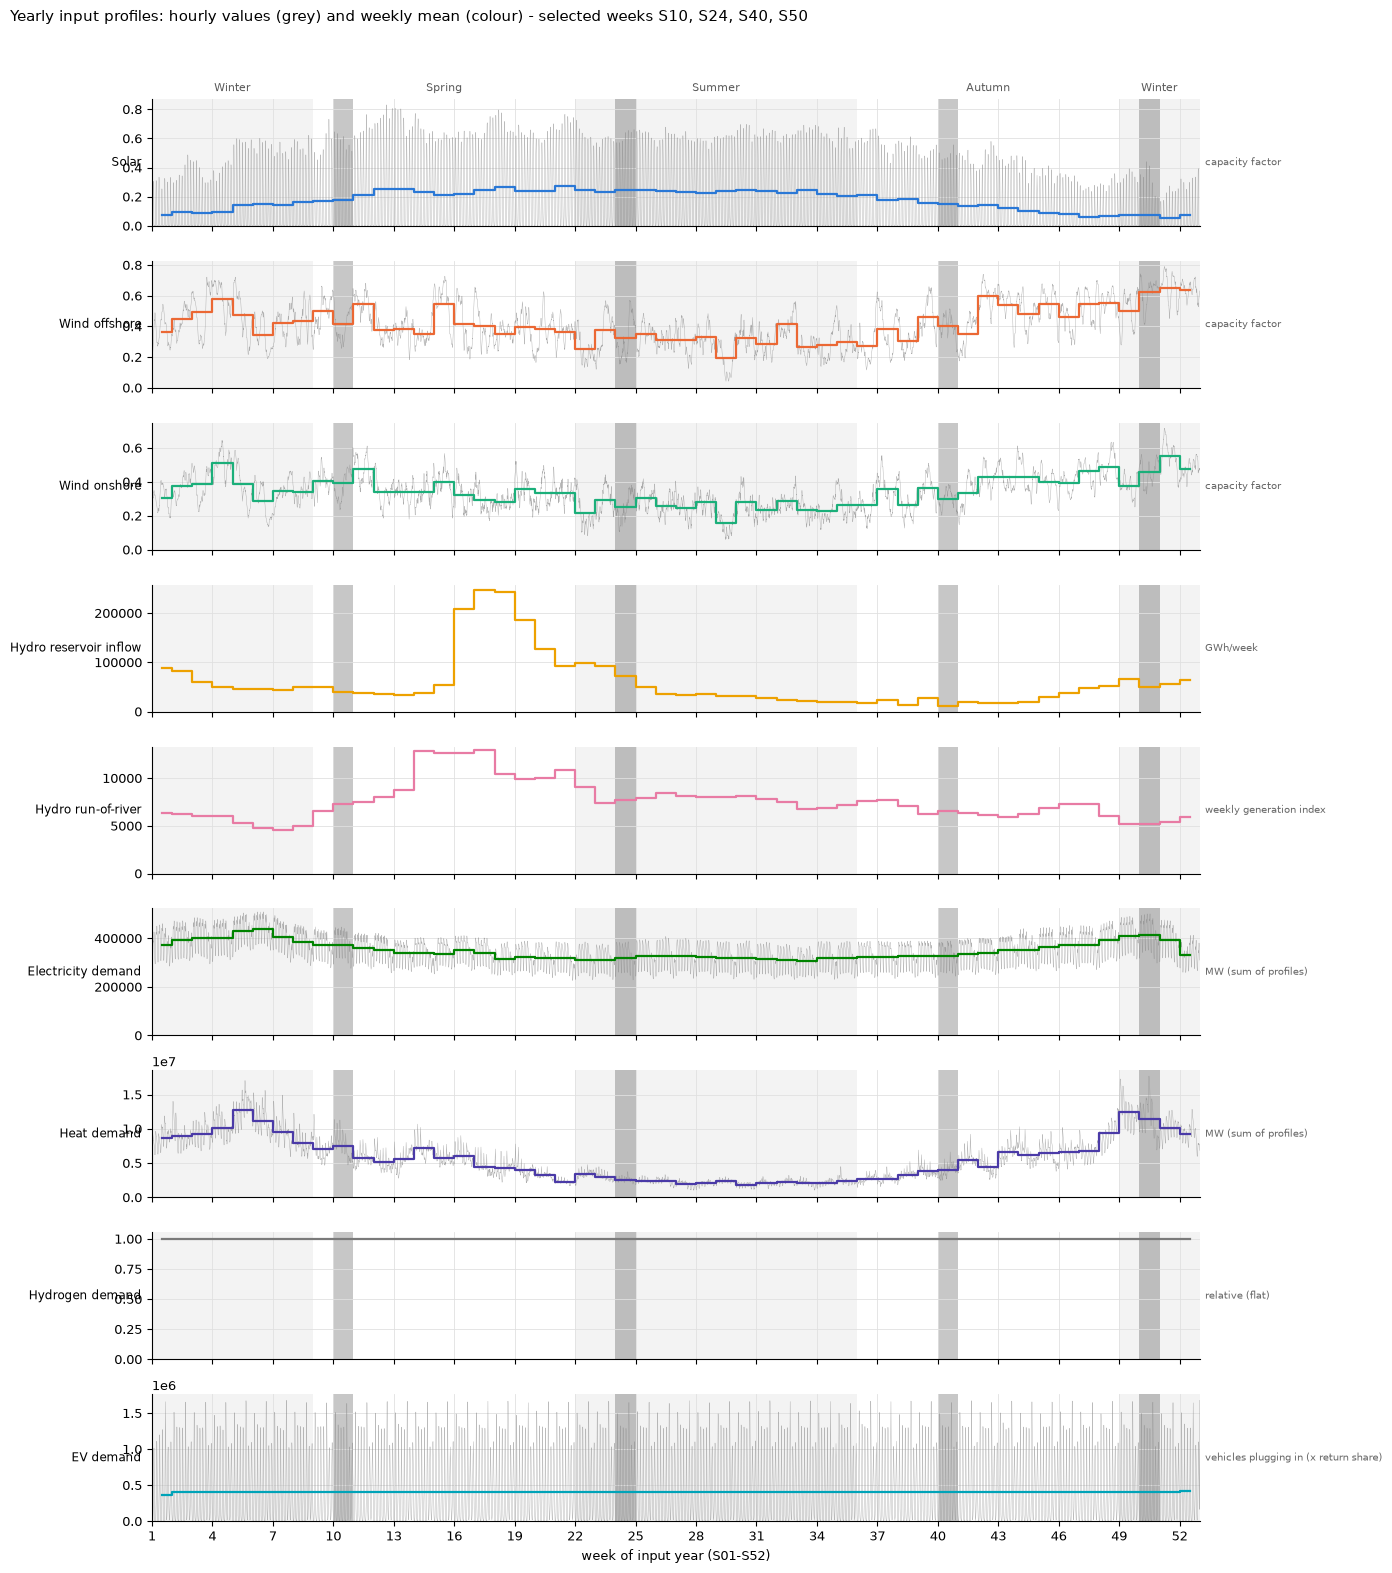

In [63]:
plot_year(selected=list(chosen_4.values()))
plt.show()

,level offset,LDC error,P5 error,P95 error,max (sel/full),min (sel/full),pass
Solar,-8.6%,4.9%,+7.8%,+0.0%,0.87,nan,True
Wind offshore,+6.3%,2.8%,-5.4%,-2.0%,0.88,3.41,True
Wind onshore,+1.8%,2.6%,-3.6%,+0.1%,0.83,1.76,True
Electricity demand,+2.5%,1.3%,+1.7%,-1.4%,0.96,0.99,True
Heat demand,+13.7%,4.6%,+1.8%,+2.8%,0.88,1.62,True
EV demand,+0.1%,0.8%,+0.0%,+0.0%,0.98,nan,True


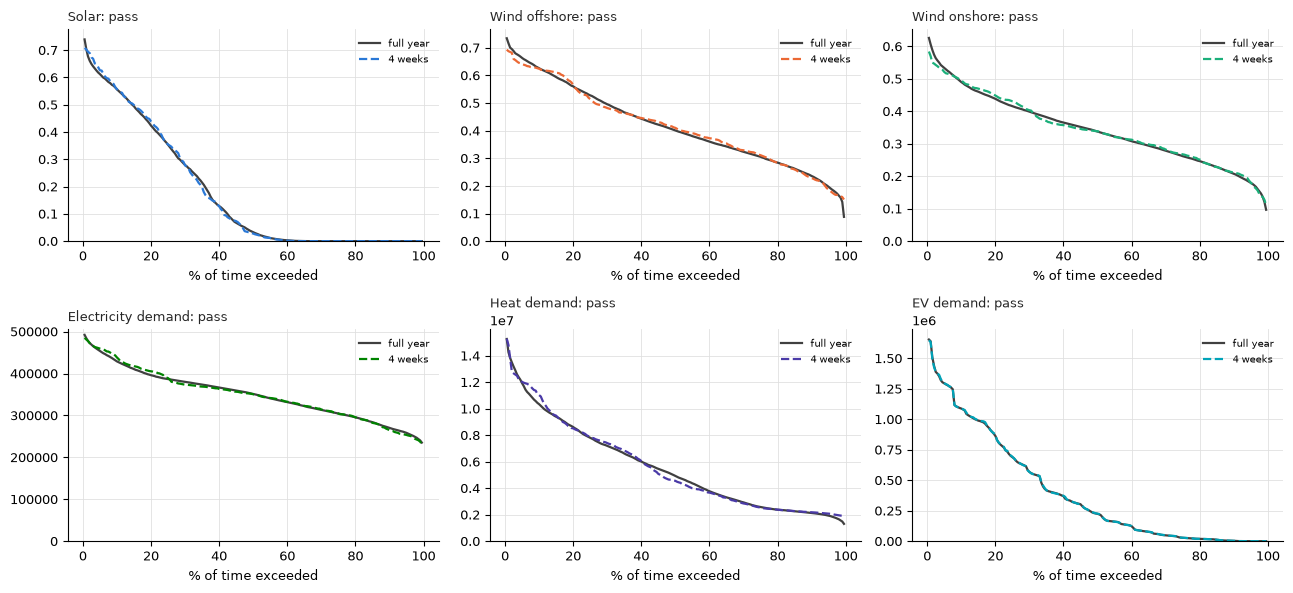

In [64]:
display(metrics_4.style.format(FMT))
show_ldc(metrics_4, curves_4, "4 weeks")
plt.show()

#### Comparison with other 4-week choices

- **pass-test selection**: the weeks above.
- **typical weeks**: per season the week closest to the season average, in standardised weekly mean and maximum of all varying inputs.
- **current**: the weeks now in `base_dc_4` (S02, S15, S28, S41).

In [65]:
def select_typical_weeks(seasons):
    """Per season: the week closest to the season's centroid in standardised feature space (weekly mean and max)."""
    feat = pd.concat({"mean": hourly[VARYING].groupby(level="week").mean(),
                      "max": hourly[VARYING].groupby(level="week").max()}, axis=1)
    z = (feat - feat.mean()) / feat.std()
    return [int(np.sqrt(((z.loc[w] - z.loc[w].mean()) ** 2).sum(axis=1)).idxmin()) for w in seasons.values()]


options = {"pass-test selection": list(chosen_4.values()), "typical weeks": select_typical_weeks(SEASONS), "current": CURRENT_4}
results = {name: compare_ldc(hourly, model_week_weights(weeks))[0] for name, weeks in options.items()}

compare = pd.concat({name: m[["level offset", "LDC error", "pass"]] for name, m in results.items()}, axis=1)
display(compare.style.format({(g, c): ("{:+.1%}" if c == "level offset" else "{:.1%}") for g in options
                              for c in ["level offset", "LDC error"]}))
print(pd.DataFrame({"weeks": {n: ", ".join(f"S{w:02d}" for w in sorted(ws)) for n, ws in options.items()},
                    f"inputs passing (of {len(TESTED)})": {n: int(m["pass"].sum()) for n, m in results.items()}}).to_string())

                                  weeks  inputs passing (of 6)
pass-test selection  S10, S24, S40, S50                      6
typical weeks        S03, S20, S30, S39                      3
current              S02, S15, S28, S41                      3


### 7. Choosing 8 weeks: two per season

Same method as for 4 weeks: same pass test, same score (most inputs passing, then smallest capped sum of violation ratios), same equal weights (`WEIGHT_S` is equal for all seasons, so each of the 8 weeks represents 6.5 weeks).

**Search.** Two weeks per season gives 66 x 78 x 91 x 78, about 36 million combinations, too many to evaluate one by one. The search therefore improves a set step by step:
1. start from a random choice of 2 weeks per season (plus one start built on the 4-week result);
2. for one season at a time, replace its 2 weeks by the best of all pairs for that season, until nothing improves;
3. polish the best few results by re-optimising two seasons together (all pairs x all pairs).

This finds a very good set but does not prove it is the best one. The notebook therefore also compares it with 30,000 random 8-week sets.

In [66]:
CURRENT_8 = [2, 8, 15, 21, 28, 34, 41, 47]                              # weeks currently in base_dc_8 / base_no_dc_8
PAIRS = [np.array(list(itertools.combinations(w, 2))) for w in SEASON_WEEKS]    # all 2-week choices per season
print(f"{np.prod([len(p) for p in PAIRS]):,} possible 8-week sets")
assert len(set(model_week_weights(list(range(1, 9))).values())) == 1             # equal weights, as in the search


def block_candidates(current, block):
    """All sets obtained by re-choosing the weeks of the seasons in `block`, keeping the other seasons as they are."""
    others = np.concatenate([current[i] for i in range(4) if i not in block])
    grids = np.meshgrid(*[np.arange(len(PAIRS[i])) for i in block], indexing="ij")
    parts = [PAIRS[i][g.ravel()] for i, g in zip(block, grids)]                   # chosen pair per season, per candidate
    return np.hstack([np.tile(others, (len(parts[0]), 1))] + parts), parts


def descent(current, blocks, max_rounds=20):
    """Block coordinate descent: replace the weeks of one block of seasons at a time while the score improves."""
    score = objective(ratios_for(np.concatenate(current)))[0]
    for _ in range(max_rounds):
        improved = False
        for block in blocks:
            cand, parts = block_candidates(current, block)
            o = objective(ratios_for(cand))
            j = int(np.argmin(o))
            if o[j] < score - 1e-9:
                score, improved = o[j], True
                for i, part in zip(block, parts):
                    current[i] = part[j]
        if not improved:
            break
    return current, score


rng = np.random.default_rng(1)
SINGLE = [(i,) for i in range(4)]
DOUBLE = list(itertools.combinations(range(4), 2))
t0 = time.time()
local_optima = []
for r in range(41):
    if r == 0:       # one start built on the 4-week result: its weeks plus one random second week per season
        start = [np.array([w, int(rng.choice([x for x in SEASON_WEEKS[i] if x != w]))]) for i, w in enumerate(best)]
    else:
        start = [PAIRS[i][rng.integers(len(PAIRS[i]))].copy() for i in range(4)]
    local_optima.append(descent(start, SINGLE))
local_optima.sort(key=lambda t: t[1])
print(f"{len(local_optima)} single-season descents in {time.time() - t0:.0f} s; best scores:", np.round([o for _, o in local_optima[:5]], 2))

polished = [descent([p.copy() for p in cur], DOUBLE + SINGLE) for cur, _ in local_optima[:3]]
polished.sort(key=lambda t: t[1])
best_8_by_season, best_8_score = polished[0]
print(f"polished in {time.time() - t0:.0f} s; best score {best_8_score:.2f}")

36,540,504 possible 8-week sets


41 single-season descents in 8 s; best scores: [-597.88 -597.88 -597.87 -597.87 -597.87]
polished in 46 s; best score -597.91


In [67]:
chosen_8 = {s: sorted(int(w) for w in pair) for s, pair in zip(SEASONS, best_8_by_season)}
weeks_8 = [w for ws in chosen_8.values() for w in ws]
weights_8 = model_week_weights(weeks_8)

# Check: the search score agrees with the full test (compare_ldc)
metrics_8, curves_8 = compare_ldc(hourly, weights_8)
r8 = ratios_for(weeks_8).iloc[0]
assert int(metrics_8.loc[SCORED, "pass"].sum()) == int((r8 <= 1).sum()), "search and compare_ldc disagree"

# Reference: 30,000 random 8-week sets (two random weeks per season). Used here as a sanity check of the search
# and in section 8 as the "untuned" benchmark.
random_sets_8 = np.hstack([PAIRS[i][rng.integers(len(PAIRS[i]), size=30000)] for i in range(4)])
ratios_random_8 = ratios_for(random_sets_8)
obj_random = objective(ratios_random_8)
print(f"best of 30,000 random 8-week sets: score {obj_random.min():.2f} ({int((ratios_random_8.iloc[obj_random.argmin()] <= 1).sum())} inputs pass); "
      f"search result: score {best_8_score:.2f} ({int((r8 <= 1).sum())} inputs pass)")
assert best_8_score <= obj_random.min() + 1e-9, "the search did not beat random sampling"

print("selected weeks:", {s: ", ".join(f"S{w:02d}" for w in ws) for s, ws in chosen_8.items()},
      "| each represents", next(iter(weights_8.values())), "weeks")

best of 30,000 random 8-week sets: score -597.49 (6 inputs pass); search result: score -597.91 (6 inputs pass)
selected weeks: {'Winter': 'S08, S50', 'Spring': 'S13, S17', 'Summer': 'S22, S28', 'Autumn': 'S37, S48'} | each represents 6.5 weeks


Selected 8 weeks (dark bands) on the yearly profiles:

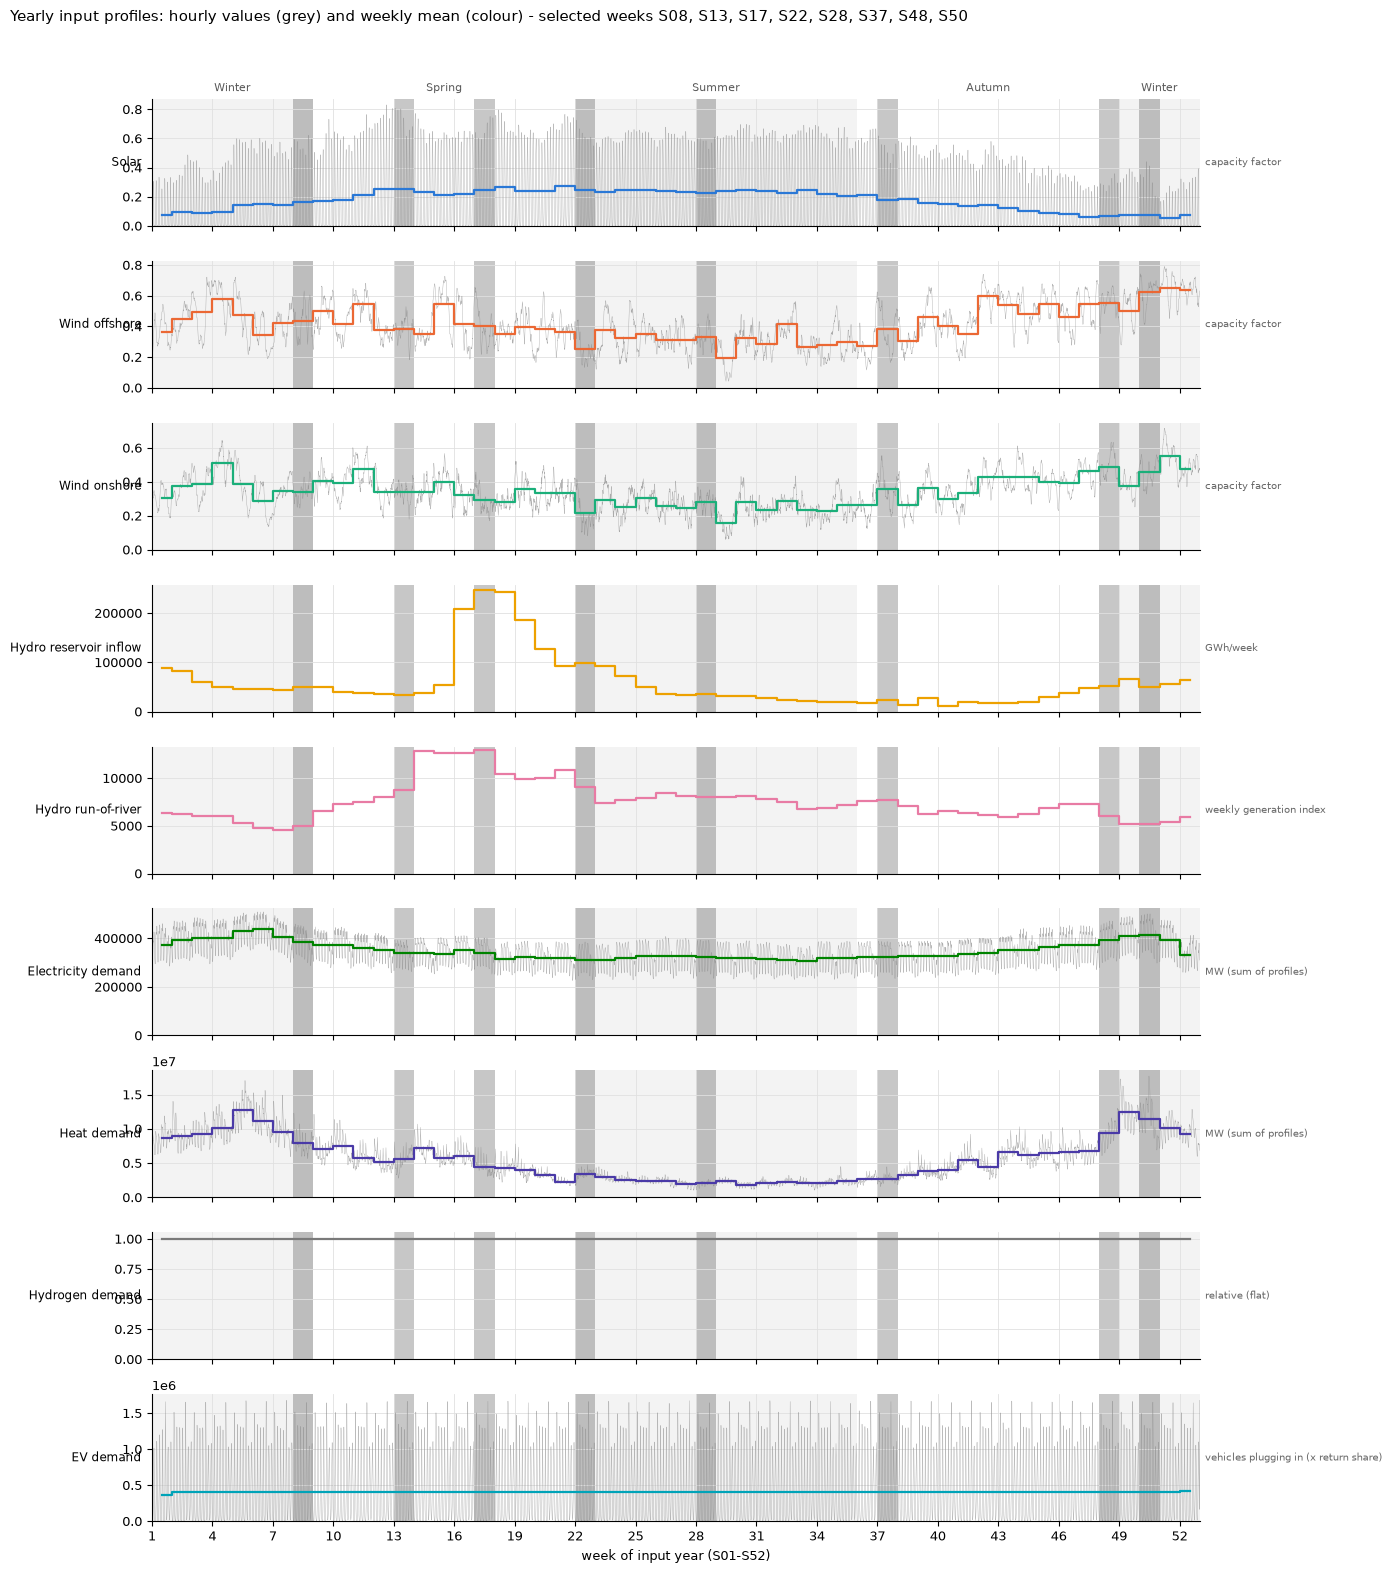

,level offset,LDC error,P5 error,P95 error,max (sel/full),min (sel/full),pass
Solar,+2.3%,2.9%,-5.1%,+0.0%,0.95,nan,True
Wind offshore,+1.2%,1.5%,-1.6%,-2.4%,0.93,3.09,True
Wind onshore,+0.8%,1.7%,+0.5%,-3.3%,0.88,1.39,True
Electricity demand,+1.0%,0.6%,+0.1%,-0.1%,0.97,1.00,True
Heat demand,+4.9%,3.1%,+4.8%,-1.1%,0.95,0.98,True
EV demand,+0.1%,0.5%,-0.8%,+0.0%,0.99,nan,True


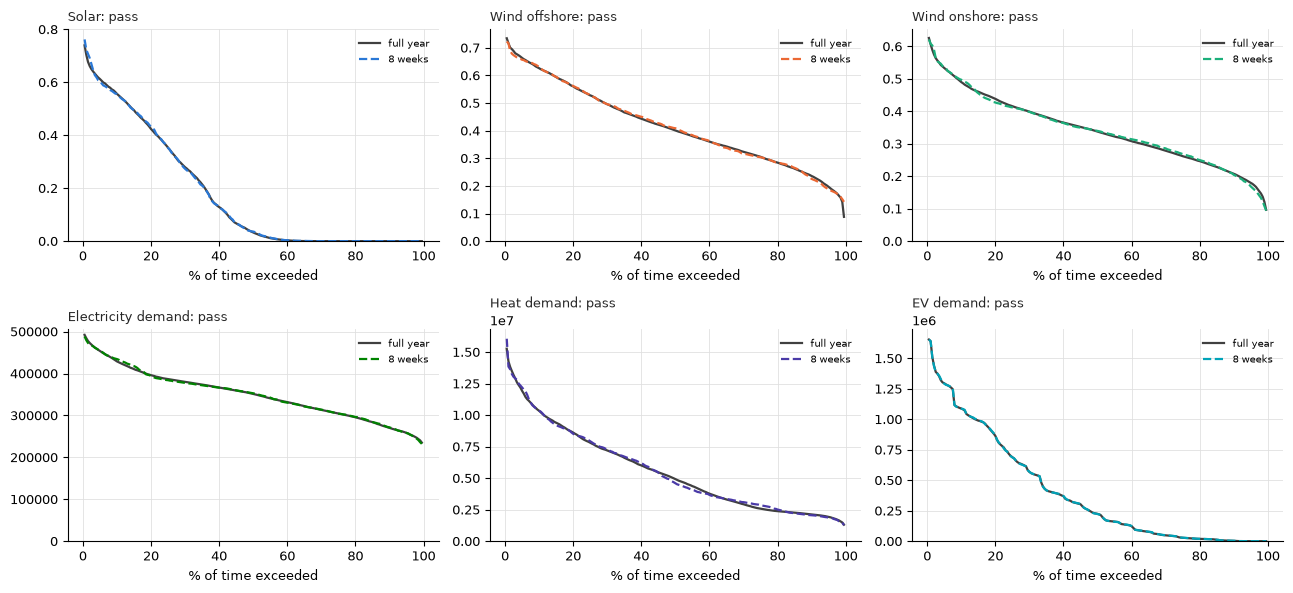

In [68]:
plot_year(selected=weeks_8)
plt.show()
display(metrics_8.style.format(FMT))
show_ldc(metrics_8, curves_8, "8 weeks")
plt.show()

### 8. What do the extra 4 weeks buy?

Four week sets are compared on the same pass test:

| Set | Weeks |
|---|---|
| current 4 | S02, S15, S28, S41 (now in `base_dc_4`) |
| selected 4 | from section 5 |
| current 8 | S02, S08, S15, S21, S28, S34, S41, S47 (now in `base_dc_8`) |
| selected 8 | from section 7 |

Because the selected sets were tuned to the test, section 8.4 also compares *arbitrary* choices (every possible 4-week set and 30,000 random 8-week sets), which shows the benefit of more weeks independent of tuning.

In [69]:
SETS = {"current 4": CURRENT_4, "selected 4": list(chosen_4.values()), "current 8": CURRENT_8, "selected 8": weeks_8}
SET_COLOR = {"4 weeks": "#eb6834", "8 weeks": "#2a78d6"}
detail = {name: compare_ldc(hourly, model_week_weights(weeks)) for name, weeks in SETS.items()}
violation = pd.DataFrame({name: ratios_for(weeks).iloc[0] for name, weeks in SETS.items()})

print("8.1 Violation ratio per input (1 or below = pass)")
table = violation.copy()
table.loc["inputs passing"] = (violation <= 1).sum()
display(table.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing"], :]))

print("8.2 Errors of the selected sets")
err = pd.concat({"selected 4": detail["selected 4"][0], "selected 8": detail["selected 8"][0]}, axis=1)
err = err.loc[:, [(k, c) for k in ["selected 4", "selected 8"] for c in ["level offset", "LDC error", "P5 error", "P95 error"]]]
display(err.style.format("{:+.1%}"))
gain = pd.DataFrame({"LDC error, 4 weeks": detail["selected 4"][0]["LDC error"], "LDC error, 8 weeks": detail["selected 8"][0]["LDC error"]})
gain["reduction"] = 1 - gain.iloc[:, 1] / gain.iloc[:, 0]
display(gain.style.format({"LDC error, 4 weeks": "{:.1%}", "LDC error, 8 weeks": "{:.1%}", "reduction": "{:.0%}"}))

8.1 Violation ratio per input (1 or below = pass)


,current 4,selected 4,current 8,selected 8
Solar,1.16,0.98,0.43,0.59
Wind offshore,0.92,0.57,0.60,0.31
Wind onshore,2.14,0.52,1.04,0.34
Electricity demand,0.33,0.27,0.29,0.13
Heat demand,3.70,0.92,3.16,0.62
EV demand,0.16,0.16,0.12,0.11
inputs passing,3,6,4,6


8.2 Errors of the selected sets


,"LDC error, 4 weeks","LDC error, 8 weeks",reduction
Solar,4.9%,2.9%,40%
Wind offshore,2.8%,1.5%,46%
Wind onshore,2.6%,1.7%,36%
Electricity demand,1.3%,0.6%,51%
Heat demand,4.6%,3.1%,33%
EV demand,0.8%,0.5%,36%


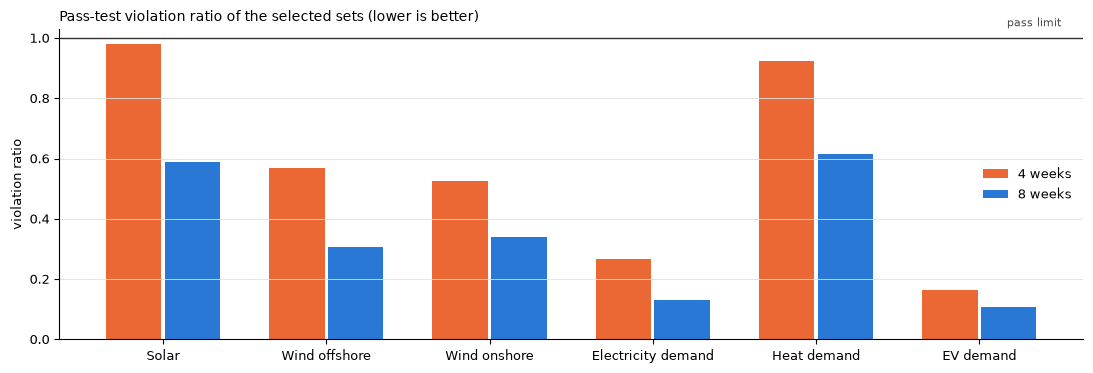

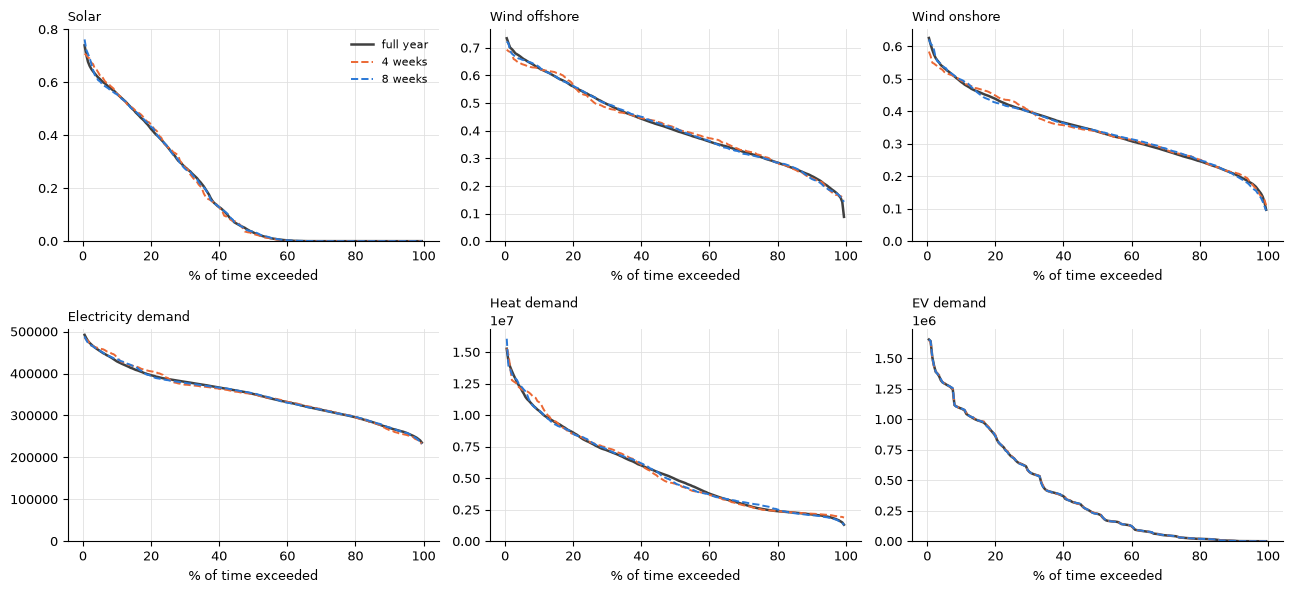

In [70]:
# 8.3 Figures: violation ratios and duration curves, 4 vs 8 selected weeks
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(SCORED))
for k, (name, key) in enumerate([("4 weeks", "selected 4"), ("8 weeks", "selected 8")]):
    ax.bar(x + (k - 0.5) * 0.36, violation.loc[SCORED, key], width=0.34, color=SET_COLOR[name], label=name)
ax.axhline(1, color="0.2", lw=1)
ax.text(len(SCORED) - 0.5, 1.03, "pass limit", ha="right", va="bottom", fontsize=8, color="0.3")
ax.set_xticks(x, SCORED)
ax.set_ylabel("violation ratio")
ax.set_title("Pass-test violation ratio of the selected sets (lower is better)", loc="left", fontsize=10)
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.flat, TESTED):
    full_c, c4 = detail["selected 4"][1][name]
    _, c8 = detail["selected 8"][1][name]
    ax.plot(Q, full_c, color="0.25", lw=1.8, label="full year")
    ax.plot(Q, c4, color=SET_COLOR["4 weeks"], lw=1.4, ls="--", label="4 weeks")
    ax.plot(Q, c8, color=SET_COLOR["8 weeks"], lw=1.4, ls="--", label="8 weeks")
    ax.set_title(name, loc="left", fontsize=9.5)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("% of time exceeded")
axes.flat[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [71]:
# 8.4 Untuned benchmark: arbitrary week choices (not optimised on the test)
random_4 = ratios                                           # all 28,392 one-per-season 4-week sets (section 5)
random_8 = ratios_random_8                                  # 30,000 random 8-week sets, two per season
bench = pd.DataFrame({
    "median ratio, 4 weeks": random_4.median(), "median ratio, 8 weeks": random_8.median(),
    "share passing, 4 weeks": (random_4 <= 1).mean(), "share passing, 8 weeks": (random_8 <= 1).mean()})
display(bench.style.format("{:.2f}", subset=["median ratio, 4 weeks", "median ratio, 8 weeks"])
        .format("{:.0%}", subset=["share passing, 4 weeks", "share passing, 8 weeks"]))

passes = pd.DataFrame({"4 weeks": (random_4 <= 1).sum(axis=1).value_counts(normalize=True),
                       "8 weeks": (random_8 <= 1).sum(axis=1).value_counts(normalize=True)}).reindex(range(len(SCORED) + 1)).fillna(0)
passes.index.name = f"inputs passing (of {len(SCORED)})"
print("Share of arbitrary week sets by number of inputs passing")
display(passes.style.format("{:.1%}"))

,"median ratio, 4 weeks","median ratio, 8 weeks","share passing, 4 weeks","share passing, 8 weeks"
Solar,2.17,1.47,11%,30%
Wind offshore,1.36,0.99,25%,51%
Wind onshore,1.25,0.91,30%,58%
Electricity demand,0.37,0.26,97%,100%
Heat demand,2.86,2.02,1%,6%
EV demand,0.16,0.12,100%,100%


Share of arbitrary week sets by number of inputs passing


,4 weeks,8 weeks
inputs passing (of 6),,
0,0.0%,0.0%
1,1.4%,0.0%
2,50.3%,20.2%
3,32.8%,30.0%
4,14.3%,35.3%
5,1.2%,13.7%
6,0.0%,0.8%


In [72]:
# 8.5 Other accuracy measures: extremes and joint behaviour of the inputs
def corr_gap(weeks):
    """Mean absolute difference between the correlation of the inputs in the selected weeks and in the full year."""
    sel = hourly.loc[hourly.index.get_level_values("week").isin(weeks), TESTED]
    diff = (sel.corr() - hourly[TESTED].corr()).abs().values
    return diff[np.triu_indices(len(TESTED), 1)].mean()


peak = pd.DataFrame({name: detail[name][0]["max (sel/full)"] for name in SETS})
print("Peak coverage: maximum in the selected weeks / maximum in the full year (1 = peak captured)")
display(peak.style.format("{:.2f}"))
print("Mean absolute error of the correlation between inputs (lower is better)")
display(pd.Series({name: corr_gap(weeks) for name, weeks in SETS.items()}).to_frame("correlation error").style.format("{:.3f}"))

Peak coverage: maximum in the selected weeks / maximum in the full year (1 = peak captured)


,current 4,selected 4,current 8,selected 8
Solar,0.83,0.87,0.95,0.95
Wind offshore,0.91,0.88,0.93,0.93
Wind onshore,0.78,0.83,0.80,0.88
Electricity demand,0.93,0.96,0.93,0.97
Heat demand,0.80,0.88,0.86,0.95
EV demand,1.00,0.98,1.00,0.99


Mean absolute error of the correlation between inputs (lower is better)


,correlation error
current 4,0.057
selected 4,0.043
current 8,0.028
selected 8,0.046


In [73]:
# 8.6 Summary
s4, s8 = violation["selected 4"], violation["selected 8"]
print(f"inputs passing:          4 weeks {int((s4 <= 1).sum())}/{len(SCORED)}  ->  8 weeks {int((s8 <= 1).sum())}/{len(SCORED)}")
print(f"mean violation ratio:    4 weeks {s4.mean():.2f}  ->  8 weeks {s8.mean():.2f}")
print("largest improvements:   ", ", ".join(f"{k} ({s4[k]:.2f} -> {s8[k]:.2f})" for k in (s4 - s8).sort_values(ascending=False).index[:3]))
print(f"arbitrary sets passing 5+ inputs:  4 weeks {(random_4 <= 1).sum(axis=1).ge(5).mean():.0%}  ->  8 weeks {(random_8 <= 1).sum(axis=1).ge(5).mean():.0%}")

inputs passing:          4 weeks 6/6  ->  8 weeks 6/6
mean violation ratio:    4 weeks 0.57  ->  8 weeks 0.35
largest improvements:    Solar (0.98 -> 0.59), Heat demand (0.92 -> 0.62), Wind offshore (0.57 -> 0.31)
arbitrary sets passing 5+ inputs:  4 weeks 1%  ->  8 weeks 15%


### 9. Simulating every 3 hours

The selected weeks stay as they are (4 weeks from section 5, 8 weeks from section 7). The model now simulates every third hour of each week (56 of the 168 hours), so the load curves are built from those hours only.

**Assumptions**
- Time-step reduction in Balmorel is a subset of T: every input is taken *at* the simulated hours and each step gets the same weight (`WEIGHT_T = 1`); the `TimeAggregation` add-on, which would average, is off. The one exception is EV demand: `EV_ipardecdef.inc` replaces the profile at each simulated hour by its mean over the hours around it (about 3 h), and the load is multiplied by `CHRONOHOUR` (= 168 / number of steps = 3 h). `reduce_to_step` does the same.
- The selected values are rescaled to the full-year mean, as in section 4.
- There are three possible starting hours: T001, T004, ... / T002, T005, ... / T003, T006, ... The best one is chosen for 4 and for 8 weeks separately, with the same score as before (most inputs passing, then smallest capped sum of violation ratios).
- Two references are shown. **Hourly full year** is the main test: how well do the 3 h weeks reproduce the real year? **Full year also at 3 h** isolates the effect of the weeks from the loss of resolution itself.

In [74]:
PHASES = {0: "T001, T004, ...", 1: "T002, T005, ...", 2: "T003, T006, ..."}


def ratio_from_metrics(m):
    "Violation ratio per input from a compare_ldc metrics table."
    return pd.concat([m["LDC error"] / THRESH["ldc"], m[["P5 error", "P95 error"]].abs().max(axis=1) / THRESH["tail"]], axis=1).max(axis=1)


results_3h = {}                                                      # (weeks label, phase, reference) -> (metrics, curves)
for label, weeks in [("4 weeks", list(chosen_4.values())), ("8 weeks", weeks_8)]:
    for phase in PHASES:
        for ref, lfl in [("hourly", False), ("3h", True)]:
            results_3h[label, phase, ref] = compare_ldc(hourly, model_week_weights(weeks), step=3, phase=phase, like_for_like=lfl)

ratio_3h = {key: ratio_from_metrics(m) for key, (m, _) in results_3h.items()}
best_phase = {}
for label in ["4 weeks", "8 weeks"]:
    scores = {phase: objective(ratio_3h[label, phase, "hourly"].values[None])[0] for phase in PHASES}
    best_phase[label] = min(scores, key=scores.get)

for ref, title in [("hourly", "9.1 Violation ratio vs the hourly full year (main test)"), ("3h", "9.2 Violation ratio vs the full year also at 3 h")]:
    table = pd.DataFrame({f"{label}, {PHASES[phase]}": ratio_3h[label, phase, ref]
                          for label in ["4 weeks", "8 weeks"] for phase in PHASES})
    table.loc["inputs passing"] = (table.iloc[:len(TESTED)] <= 1).sum()
    print(title)
    display(table.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing"], :]))
print("best starting hours:", {label: PHASES[p] for label, p in best_phase.items()})

9.1 Violation ratio vs the hourly full year (main test)


,"4 weeks, T001, T004, ...","4 weeks, T002, T005, ...","4 weeks, T003, T006, ...","8 weeks, T001, T004, ...","8 weeks, T002, T005, ...","8 weeks, T003, T006, ..."
Solar,1.54,1.14,2.23,1.61,1.05,2.69
Wind offshore,0.61,0.57,0.57,0.32,0.33,0.31
Wind onshore,0.54,0.51,0.53,0.35,0.34,0.37
Electricity demand,0.30,0.31,0.29,0.13,0.17,0.17
Heat demand,0.94,0.97,0.98,0.63,0.65,0.65
EV demand,3.14,3.14,2.46,3.12,3.16,2.54
inputs passing,4,4,4,4,4,4


9.2 Violation ratio vs the full year also at 3 h


,"4 weeks, T001, T004, ...","4 weeks, T002, T005, ...","4 weeks, T003, T006, ...","8 weeks, T001, T004, ...","8 weeks, T002, T005, ...","8 weeks, T003, T006, ..."
Solar,1.88,1.39,2.01,1.09,0.90,1.13
Wind offshore,0.61,0.57,0.57,0.32,0.32,0.31
Wind onshore,0.54,0.52,0.53,0.35,0.34,0.42
Electricity demand,0.30,0.30,0.29,0.13,0.14,0.16
Heat demand,0.94,0.97,0.99,0.60,0.68,0.67
EV demand,0.57,0.78,0.77,0.34,0.52,0.42
inputs passing,5,5,5,5,6,5


best starting hours: {'4 weeks': 'T002, T005, ...', '8 weeks': 'T002, T005, ...'}


Violation ratio (1 or below = pass); 3 h with the best starting hour of each set


,"4 weeks, hourly","4 weeks, 3 h","8 weeks, hourly","8 weeks, 3 h"
Solar,0.98,1.14,0.59,1.05
Wind offshore,0.57,0.57,0.31,0.33
Wind onshore,0.52,0.51,0.34,0.34
Electricity demand,0.27,0.31,0.13,0.17
Heat demand,0.92,0.97,0.62,0.65
EV demand,0.16,3.14,0.11,3.16
inputs passing,6,4,6,4


Errors against the hourly full year


,"LDC error, 4 weeks","LDC error, 8 weeks",reduction
Solar,5.7%,5.3%,7%
Wind offshore,2.8%,1.7%,41%
Wind onshore,2.6%,1.7%,33%
Electricity demand,1.5%,0.8%,46%
Heat demand,4.8%,3.3%,32%
EV demand,15.7%,15.8%,-1%


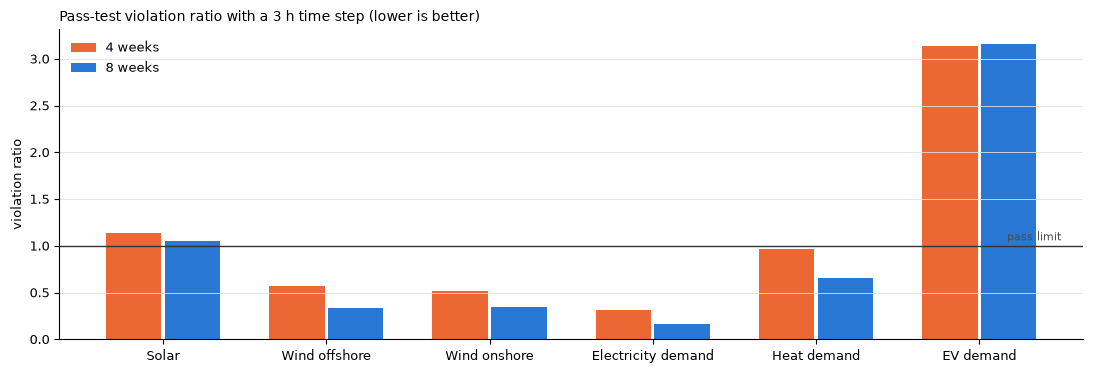

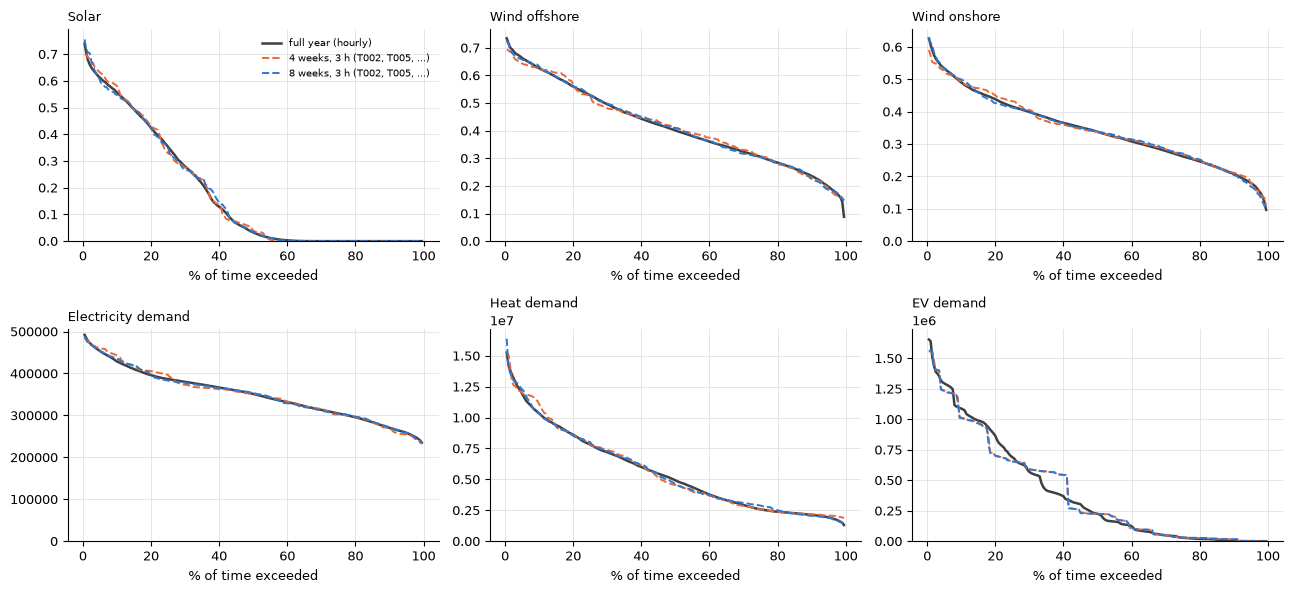

In [75]:
# 9.3 Selected starting hours: 3 h against hourly, for 4 and 8 weeks
hourly_ratio = {"4 weeks": ratios_for(list(chosen_4.values())).iloc[0], "8 weeks": ratios_for(weeks_8).iloc[0]}
compare_3h = pd.DataFrame({
    "4 weeks, hourly": hourly_ratio["4 weeks"], "4 weeks, 3 h": ratio_3h["4 weeks", best_phase["4 weeks"], "hourly"],
    "8 weeks, hourly": hourly_ratio["8 weeks"], "8 weeks, 3 h": ratio_3h["8 weeks", best_phase["8 weeks"], "hourly"]})
compare_3h.loc["inputs passing"] = (compare_3h.iloc[:len(TESTED)] <= 1).sum()
print("Violation ratio (1 or below = pass); 3 h with the best starting hour of each set")
display(compare_3h.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing"], :]))

m4, c4 = results_3h["4 weeks", best_phase["4 weeks"], "hourly"]
m8, c8 = results_3h["8 weeks", best_phase["8 weeks"], "hourly"]
err = pd.concat({"4 weeks, 3 h": m4, "8 weeks, 3 h": m8}, axis=1)
err = err.loc[:, [(k, c) for k in ["4 weeks, 3 h", "8 weeks, 3 h"] for c in ["level offset", "LDC error", "P5 error", "P95 error"]]]
print("Errors against the hourly full year")
display(err.style.format("{:+.1%}"))
gain = pd.DataFrame({"LDC error, 4 weeks": m4["LDC error"], "LDC error, 8 weeks": m8["LDC error"]})
gain["reduction"] = 1 - gain.iloc[:, 1] / gain.iloc[:, 0]
display(gain.style.format({"LDC error, 4 weeks": "{:.1%}", "LDC error, 8 weeks": "{:.1%}", "reduction": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(TESTED))
for k, (name, col) in enumerate([("4 weeks", "4 weeks, 3 h"), ("8 weeks", "8 weeks, 3 h")]):
    ax.bar(x + (k - 0.5) * 0.36, compare_3h.loc[TESTED, col], width=0.34, color=SET_COLOR[name], label=name)
ax.axhline(1, color="0.2", lw=1)
ax.text(len(TESTED) - 0.5, 1.03, "pass limit", ha="right", va="bottom", fontsize=8, color="0.3")
ax.set_xticks(x, TESTED)
ax.set_ylabel("violation ratio")
ax.set_title("Pass-test violation ratio with a 3 h time step (lower is better)", loc="left", fontsize=10)
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.flat, TESTED):
    full_c, s4 = c4[name]
    _, s8 = c8[name]
    ax.plot(Q, full_c, color="0.25", lw=1.8, label="full year (hourly)")
    ax.plot(Q, s4, color=SET_COLOR["4 weeks"], lw=1.4, ls="--", label=f"4 weeks, 3 h ({PHASES[best_phase['4 weeks']]})")
    ax.plot(Q, s8, color=SET_COLOR["8 weeks"], lw=1.4, ls="--", label=f"8 weeks, 3 h ({PHASES[best_phase['8 weeks']]})")
    ax.set_title(name, loc="left", fontsize=9.5)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("% of time exceeded")
axes.flat[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

In [76]:
# 9.4 Summary
a4, a8 = compare_3h["4 weeks, 3 h"].iloc[:len(TESTED)], compare_3h["8 weeks, 3 h"].iloc[:len(TESTED)]
h4, h8 = compare_3h["4 weeks, hourly"].iloc[:len(TESTED)], compare_3h["8 weeks, hourly"].iloc[:len(TESTED)]
print(f"inputs passing, hourly:  4 weeks {int((h4 <= 1).sum())}/{len(TESTED)}  8 weeks {int((h8 <= 1).sum())}/{len(TESTED)}")
print(f"inputs passing, 3 h:     4 weeks {int((a4 <= 1).sum())}/{len(TESTED)}  8 weeks {int((a8 <= 1).sum())}/{len(TESTED)}")
l4, l8 = ratio_3h["4 weeks", best_phase["4 weeks"], "3h"], ratio_3h["8 weeks", best_phase["8 weeks"], "3h"]
print(f"inputs passing, 3 h vs the full year also at 3 h: 4 weeks {int((l4 <= 1).sum())}/{len(TESTED)}  8 weeks {int((l8 <= 1).sum())}/{len(TESTED)}")
print(f"mean violation ratio:    4 weeks {h4.mean():.2f} -> {a4.mean():.2f} (3 h)   8 weeks {h8.mean():.2f} -> {a8.mean():.2f} (3 h)")
print("cost of the 3 h step (ratio change):", ", ".join(f"{k} {a8[k] - h8[k]:+.2f}" for k in (a8 - h8).sort_values(ascending=False).index[:3]), "(8 weeks, worst three)")

inputs passing, hourly:  4 weeks 6/6  8 weeks 6/6
inputs passing, 3 h:     4 weeks 4/6  8 weeks 4/6
inputs passing, 3 h vs the full year also at 3 h: 4 weeks 5/6  8 weeks 6/6
mean violation ratio:    4 weeks 0.57 -> 1.10 (3 h)   8 weeks 0.35 -> 0.95 (3 h)
cost of the 3 h step (ratio change): EV demand +3.05, Solar +0.47, Heat demand +0.04 (8 weeks, worst three)


### 10. All hours of the week or only three days?

So far the model simulated every third hour of the **whole week** (56 steps per week). A cheaper alternative keeps only **three days of each week** (2 weekdays and 1 weekend day), still every third hour (24 steps per week, 43 % of the size). This section tests what is lost.

**Assumptions**
- Hour 1 of every week is Monday 00:00 (as in the `TimeAggregation` add-on and the EV notebook). Monday is T001-T024, Tuesday T025-T048, ..., Sunday T145-T168.
- The base case is **Thursday, Friday and Saturday**: this is exactly the time set now in `base_dc_8` (T073, T076, ..., T142), checked below. All 20 ways of choosing 2 weekdays and 1 weekend day are tested in 10.3.
- The selected weeks (4 and 8) and the starting hour within the day (best of three, chosen as in section 9) are used for both configurations; only the hours kept per week differ.
- As in section 9, EV demand is averaged over the hours around each simulated hour (`EV_ipardecdef.inc`) and everything else is sampled. With gaps between the kept days, the window of the first and last step of each block reaches halfway across the gap.
- Model note: `CHRONOHOUR = 168 / number of steps`, so with 24 steps every step counts as 7 h (3 h for the full week). Energy accounting stays correct, but storage and EV flexibility then see 7 h steps while the data are 3 h apart. This is not part of the test below.
- A real week has 5 weekdays and 2 weekend days (71 % weekdays); 2 weekdays and 1 weekend day (67 %) keeps the mix close.

In [77]:
DAY_START = {"Mon": 1, "Tue": 25, "Wed": 49, "Thu": 73, "Fri": 97, "Sat": 121, "Sun": 145}      # first hour of each day
WEEKDAYS, WEEKEND = ["Mon", "Tue", "Wed", "Thu", "Fri"], ["Sat", "Sun"]
BASE_DAYS = ("Thu", "Fri", "Sat")
STEP = 3


def day_hours(days, phase, step=STEP):
    "Hours (1-168) simulated when only `days` of the week are kept, every `step`-th hour, starting `phase` hours into the day."
    return [DAY_START[d] + phase + step * k for d in days for k in range(24 // step)]


def active_T(path):
    "Simulated T of a scenario: the T numbers on the lines that are not commented out."
    lines = [l for l in Path(path).read_text(encoding="latin1").splitlines() if not l.lstrip().startswith("*")]
    return [int(x) for l in lines for x in re.findall(r"\bT(\d{3})\b", l)]


for scenario in ["base_dc_8", "base_no_dc_8"]:
    ok = active_T(ROOT / scenario / "data" / "T.inc") == day_hours(BASE_DAYS, 0)
    print(f"{scenario}: time set equals Thu-Fri-Sat every 3 h (T073-T142): {ok}")


def run_config(weeks, days, reference):
    "Ratios of the pass test for the 3 starting hours; days=None keeps all hours of the week. Returns {phase: (ratio, metrics, curves)}."
    out = {}
    for phase in PHASES:
        hours = simulated_hours(STEP, phase) if days is None else day_hours(days, phase)
        m, c = compare_ldc(hourly, model_week_weights(weeks), step=STEP, phase=phase,
                           like_for_like=(reference == "3h"), hours=hours)
        out[phase] = (ratio_from_metrics(m), m, c)
    return out


def best_phase_of(runs):
    "Starting hour with the best score (most inputs passing, then smallest capped sum of ratios)."
    return min(runs, key=lambda p: objective(runs[p][0].values[None])[0])


WEEK_SETS = {"4 weeks": list(chosen_4.values()), "8 weeks": weeks_8}
CONFIGS = {"full week": None, "3 days (Thu-Fri-Sat)": BASE_DAYS}
runs = {(w, c, ref): run_config(WEEK_SETS[w], days, ref) for w in WEEK_SETS for c, days in CONFIGS.items() for ref in ["hourly", "3h"]}
best_start = {(w, c): best_phase_of(runs[w, c, "hourly"]) for w in WEEK_SETS for c in CONFIGS}      # starting hour chosen against the hourly year
print("best starting hours:", {f"{w}, {c}": PHASES[p] for (w, c), p in best_start.items()})

base_dc_8: time set equals Thu-Fri-Sat every 3 h (T073-T142): True
base_no_dc_8: time set equals Thu-Fri-Sat every 3 h (T073-T142): True
best starting hours: {'4 weeks, full week': 'T002, T005, ...', '4 weeks, 3 days (Thu-Fri-Sat)': 'T001, T004, ...', '8 weeks, full week': 'T002, T005, ...', '8 weeks, 3 days (Thu-Fri-Sat)': 'T002, T005, ...'}


#### 10.1 Full week against three days

Violation ratio of the pass test (1 or below = pass), with the best starting hour of each configuration. **Hourly full year** is the main test; **full year also at 3 h** removes the loss of resolution that both configurations share and shows what the missing days cost.

In [78]:
def comparison_table(ref):
    cols = {f"{w}, {c}": runs[w, c, ref][best_start[w, c]][0] for w in WEEK_SETS for c in CONFIGS}
    table = pd.DataFrame(cols)
    table.loc["inputs passing"] = (table <= 1).sum()
    table.loc["mean ratio"] = table.iloc[:len(TESTED)].mean()
    return table


for ref, title in [("hourly", "Reference: hourly full year"), ("3h", "Reference: full year also at 3 h")]:
    print(title)
    display(comparison_table(ref).style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing"], :]))

Reference: hourly full year


,"4 weeks, full week","4 weeks, 3 days (Thu-Fri-Sat)","8 weeks, full week","8 weeks, 3 days (Thu-Fri-Sat)"
Solar,1.14,1.75,1.05,1.26
Wind offshore,0.57,1.28,0.33,1.36
Wind onshore,0.51,2.17,0.34,2.05
Electricity demand,0.31,0.31,0.17,0.23
Heat demand,0.97,1.55,0.65,1.03
EV demand,3.14,3.99,3.16,4.67
inputs passing,4,1,4,1
mean ratio,1.10,1.84,0.95,1.77


Reference: full year also at 3 h


,"4 weeks, full week","4 weeks, 3 days (Thu-Fri-Sat)","8 weeks, full week","8 weeks, 3 days (Thu-Fri-Sat)"
Solar,1.39,2.10,0.90,0.91
Wind offshore,0.57,1.27,0.32,1.34
Wind onshore,0.52,2.12,0.34,2.01
Electricity demand,0.30,0.29,0.14,0.22
Heat demand,0.97,1.55,0.68,1.05
EV demand,0.78,3.79,0.52,3.68
inputs passing,5,1,6,2
mean ratio,0.76,1.85,0.48,1.54


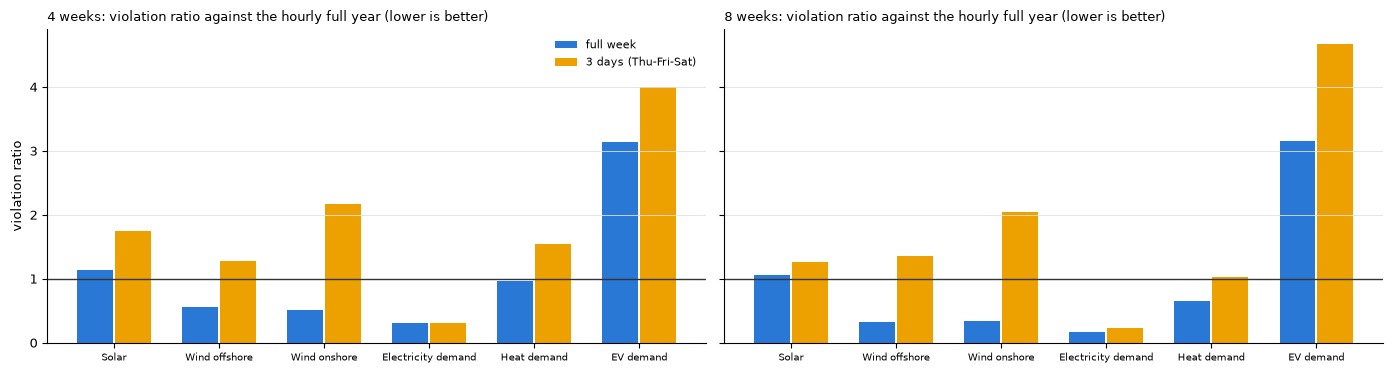

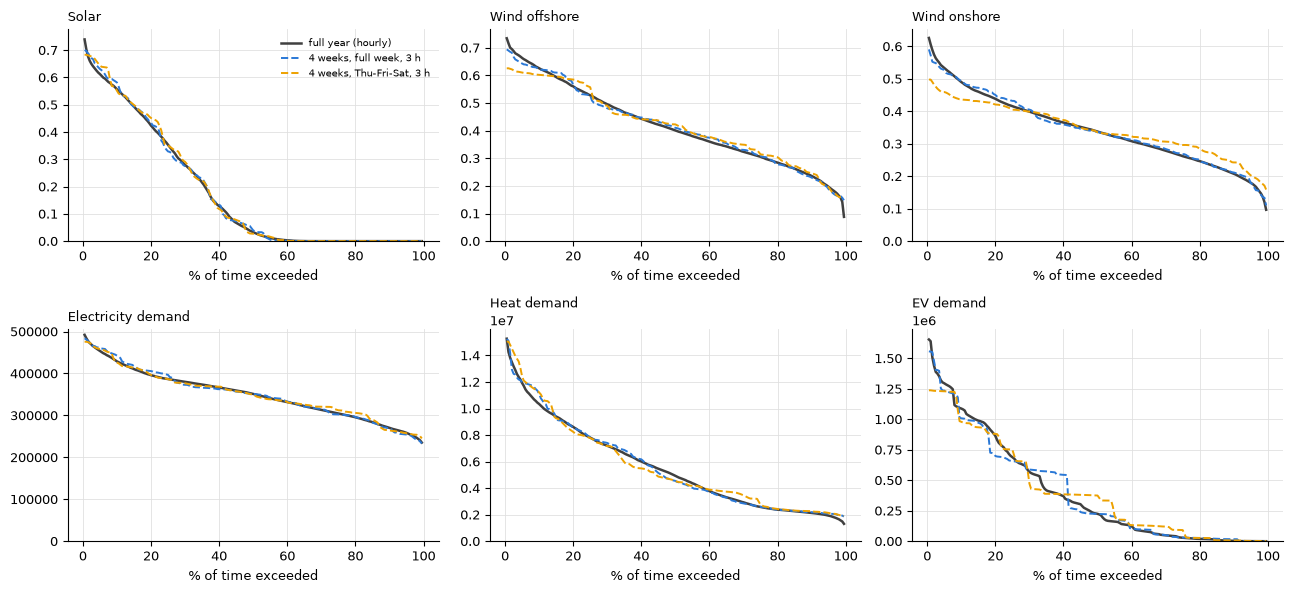

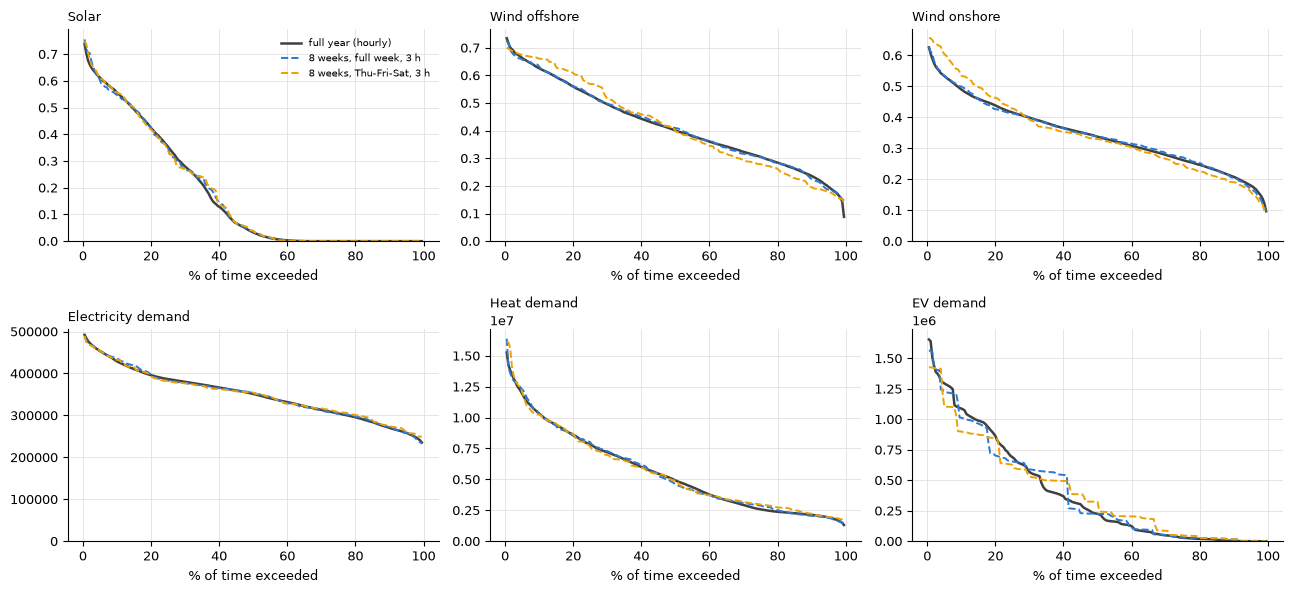

In [79]:
# 10.2 Figures: violation ratio and load-duration curves, full week vs three days
DAY_COLOR = {"full week": "#2a78d6", "3 days (Thu-Fri-Sat)": "#eda100"}
table = comparison_table("hourly")
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, w in zip(axes, WEEK_SETS):
    x = np.arange(len(TESTED))
    for k, c in enumerate(CONFIGS):
        ax.bar(x + (k - 0.5) * 0.36, table.loc[TESTED, f"{w}, {c}"], width=0.34, color=DAY_COLOR[c], label=c)
    ax.axhline(1, color="0.2", lw=1)
    ax.set_xticks(x, TESTED, fontsize=7.5)
    ax.set_title(f"{w}: violation ratio against the hourly full year (lower is better)", loc="left", fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_ylabel("violation ratio")
plt.tight_layout()
plt.show()

for w in WEEK_SETS:
    fig, axes = plt.subplots(2, 3, figsize=(13, 6))
    curves_full = runs[w, "full week", "hourly"][best_start[w, "full week"]][2]
    curves_days = runs[w, "3 days (Thu-Fri-Sat)", "hourly"][best_start[w, "3 days (Thu-Fri-Sat)"]][2]
    for ax, name in zip(axes.flat, TESTED):
        ax.plot(Q, curves_full[name][0], color="0.25", lw=1.8, label="full year (hourly)")
        ax.plot(Q, curves_full[name][1], color=DAY_COLOR["full week"], lw=1.4, ls="--", label=f"{w}, full week, 3 h")
        ax.plot(Q, curves_days[name][1], color=DAY_COLOR["3 days (Thu-Fri-Sat)"], lw=1.4, ls="--", label=f"{w}, Thu-Fri-Sat, 3 h")
        ax.set_title(name, loc="left", fontsize=9.5)
        ax.set_ylim(bottom=0)
        ax.set_xlabel("% of time exceeded")
    axes.flat[0].legend(frameon=False, fontsize=7)
    plt.tight_layout()
    plt.show()

#### 10.3 Does the choice of days matter?

All 20 ways to keep 2 weekdays and 1 weekend day, each with its best starting hour, against the hourly full year. The Thu-Fri-Sat case is marked; the full-week result is the reference.

In [80]:
day_choices = [(a, b, c) for a, b in itertools.combinations(WEEKDAYS, 2) for c in WEEKEND]
sens = {}
for w in WEEK_SETS:
    rows = {}
    for days in day_choices:
        r = run_config(WEEK_SETS[w], days, "hourly")
        bp = best_phase_of(r)
        rows["-".join(days)] = r[bp][0]
    sens[w] = pd.DataFrame(rows).T                                           # rows = day choices, columns = inputs

for w in WEEK_SETS:
    t = sens[w]
    summary = pd.DataFrame({"inputs passing": (t <= 1).sum(axis=1), "mean ratio": t.mean(axis=1)})
    summary = summary.sort_values(["inputs passing", "mean ratio"], ascending=[False, True])
    full = table.loc[["inputs passing", "mean ratio"], f"{w}, full week"]
    print(f"{w}: full week passes {int(full['inputs passing'])}/{len(TESTED)}, mean ratio {full['mean ratio']:.2f}")
    show = pd.concat([summary.head(4), summary.loc[["Thu-Fri-Sat"]], summary.tail(3)]).loc[lambda d: ~d.index.duplicated()]
    display(show.style.format({"mean ratio": "{:.2f}", "inputs passing": "{:.0f}"}))
    print(f"   3 days, over the {len(day_choices)} choices: inputs passing {int(summary['inputs passing'].min())}-{int(summary['inputs passing'].max())}, "
          f"mean ratio best {summary['mean ratio'].min():.2f} / median {summary['mean ratio'].median():.2f} / worst {summary['mean ratio'].max():.2f}")

4 weeks: full week passes 4/6, mean ratio 1.10


,inputs passing,mean ratio
Tue-Fri-Sun,4,1.98
Mon-Fri-Sun,3,1.96
Wed-Thu-Sun,3,2.11
Wed-Fri-Sun,2,1.73
Thu-Fri-Sat,1,1.84
Tue-Fri-Sat,1,1.91
Thu-Fri-Sun,1,1.92
Tue-Thu-Sun,1,2.35


   3 days, over the 20 choices: inputs passing 1-4, mean ratio best 1.73 / median 1.97 / worst 2.35
8 weeks: full week passes 4/6, mean ratio 0.95


,inputs passing,mean ratio
Thu-Fri-Sun,4,1.40
Mon-Fri-Sun,4,1.50
Mon-Tue-Sat,4,1.55
Mon-Wed-Sat,4,1.59
Thu-Fri-Sat,1,1.77
Wed-Fri-Sat,2,1.98
Mon-Tue-Sun,1,1.72


   3 days, over the 20 choices: inputs passing 1-4, mean ratio best 1.40 / median 1.72 / worst 1.99


In [81]:
# 10.4 Which inputs lose most when only three days are kept
rows = {}
for w in WEEK_SETS:
    rows[f"{w}, full week"] = table[f"{w}, full week"]
    rows[f"{w}, Thu-Fri-Sat"] = table[f"{w}, 3 days (Thu-Fri-Sat)"]
    rows[f"{w}, 3 days, all 20 choices: median"] = sens[w].median()
    rows[f"{w}, 3 days, all 20 choices: worst"] = sens[w].max()
display(pd.DataFrame(rows).loc[TESTED].style.format("{:.2f}"))

ref3 = comparison_table("3h")
print("Against the full year also at 3 h (what the missing days cost):")
for w in WEEK_SETS:
    full_col, days_col = ref3[f"{w}, full week"], ref3[f"{w}, 3 days (Thu-Fri-Sat)"]
    worse = (days_col - full_col).iloc[:len(TESTED)].sort_values(ascending=False)
    print(f"  {w}: inputs passing {int(full_col['inputs passing'])}/{len(TESTED)} -> {int(days_col['inputs passing'])}/{len(TESTED)}; "
          f"mean ratio {full_col['mean ratio']:.2f} -> {days_col['mean ratio']:.2f}; largest increases: "
          + ", ".join(f"{k} {full_col[k]:.2f} -> {days_col[k]:.2f}" for k in worse.index[:3]))

,"4 weeks, full week","4 weeks, Thu-Fri-Sat","4 weeks, 3 days, all 20 choices: median","4 weeks, 3 days, all 20 choices: worst","8 weeks, full week","8 weeks, Thu-Fri-Sat","8 weeks, 3 days, all 20 choices: median","8 weeks, 3 days, all 20 choices: worst"
Solar,1.14,1.75,1.60,2.90,1.05,1.26,1.25,2.90
Wind offshore,0.57,1.28,1.01,1.60,0.33,1.36,0.76,1.36
Wind onshore,0.51,2.17,1.10,2.17,0.34,2.05,0.89,2.50
Electricity demand,0.31,0.31,0.38,0.47,0.17,0.23,0.24,0.33
Heat demand,0.97,1.55,1.48,1.95,0.65,1.03,1.01,1.30
EV demand,3.14,3.99,6.30,7.72,3.16,4.67,6.16,7.49


Against the full year also at 3 h (what the missing days cost):
  4 weeks: inputs passing 5/6 -> 1/6; mean ratio 0.76 -> 1.85; largest increases: EV demand 0.78 -> 3.79, Wind onshore 0.52 -> 2.12, Solar 1.39 -> 2.10
  8 weeks: inputs passing 6/6 -> 2/6; mean ratio 0.48 -> 1.54; largest increases: EV demand 0.52 -> 3.68, Wind onshore 0.34 -> 2.01, Wind offshore 0.32 -> 1.34


### 11. Three days or the full week, every hour (4 selected weeks)

Section 10 compared the full week with three days at a 3 h step. This section repeats the comparison **at hourly resolution**, so the only difference between the two configurations is the missing days:

| Configuration | Hours kept per week | Steps per week |
|---|---|---|
| full week, hourly | T001-T168 | 168 |
| 3 days, hourly | 2 weekdays + 1 weekend day, all 24 hours of each | 72 (43 %) |

**Assumptions**
- The weeks are the 4 selected in section 5 (one per season), with equal weights (`WEIGHT_S`).
- Days as in section 10: hour 1 of every week is Monday 00:00, and the base case is **Thursday, Friday and Saturday** (the days in `base_dc_8`). All 20 ways of choosing 2 weekdays and 1 weekend day are also tested.
- Same pass test as before (rescaled load-duration curves against the hourly full year, section 4). Inputs are taken at the simulated hours; EV demand is averaged over the hours around each simulated hour (`EV_ipardecdef.inc`), so at an hourly step it is unchanged inside the kept days, and the window of the first and last hour of each block reaches halfway across the gap to the next kept day.
- Model note: with 72 steps `CHRONOHOUR = 168 / 72 = 2.33`, so every simulated hour counts as 2.33 h. Energy totals stay correct, but storage and EV flexibility see 2.33 h steps while the data are 1 h apart. This is not part of the test.
- Because the full week at hourly resolution is the reference the weeks were tuned on (section 5), its result is the best case. The question is how far the 3-day version falls behind it.

In [82]:
# 11.1 Violation ratios: full week vs three days, both hourly, 4 selected weeks
weeks_4 = list(chosen_4.values())
weights_4h = model_week_weights(weeks_4)

def hourly_config(days):
    "Pass test at hourly resolution keeping only `days` of each selected week (None = full week). Returns (ratio, metrics, curves)."
    hours = None if days is None else day_hours(days, 0, step=1)
    m, c = compare_ldc(hourly, weights_4h, step=1, hours=hours)
    return ratio_from_metrics(m), m, c

assert day_hours(BASE_DAYS, 0, step=1) == list(range(73, 145))          # Thu-Fri-Sat = T073-T144
hourly_full = hourly_config(None)
hourly_days = hourly_config(BASE_DAYS)
assert np.allclose(hourly_full[0][SCORED].values, ratios_for(weeks_4).iloc[0][SCORED].values)   # same as section 5

# All 20 choices of 2 weekdays + 1 weekend day, hourly
sens_1h = pd.DataFrame({"-".join(d): hourly_config(d)[0] for d in day_choices}).T     # rows = day choices, columns = inputs

table_1h = pd.DataFrame({
    "full week, 1 h": hourly_full[0],
    "Thu-Fri-Sat, 1 h": hourly_days[0],
    "3 days, all 20 choices: best": sens_1h.min(),
    "3 days, all 20 choices: median": sens_1h.median(),
    "3 days, all 20 choices: worst": sens_1h.max(),
})
table_1h.loc["inputs passing"] = (table_1h.iloc[:len(TESTED)] <= 1).sum()
table_1h.loc["mean ratio"] = table_1h.iloc[:len(TESTED)].mean()
print("Violation ratio against the hourly full year (1 or below = pass); 'best/median/worst' are per input over the 20 day choices")
display(table_1h.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing"], :]))

err_1h = pd.concat({"full week, 1 h": hourly_full[1], "Thu-Fri-Sat, 1 h": hourly_days[1]}, axis=1)
err_1h = err_1h.loc[:, [(k, c) for k in ["full week, 1 h", "Thu-Fri-Sat, 1 h"] for c in ["level offset", "LDC error", "P5 error", "P95 error"]]]
print("Errors against the hourly full year (level offset is removed by the rescaling and not tested)")
display(err_1h.style.format("{:+.1%}"))

ranking = pd.DataFrame({"inputs passing": (sens_1h <= 1).sum(axis=1), "mean ratio": sens_1h.mean(axis=1)}) \
            .sort_values(["inputs passing", "mean ratio"], ascending=[False, True])
ranking["rank"] = np.arange(1, len(ranking) + 1)
print(f"Day choices ranked (hourly, 4 weeks); Thu-Fri-Sat is rank {int(ranking.loc['Thu-Fri-Sat', 'rank'])} of {len(ranking)}")
display(ranking.style.format({"mean ratio": "{:.2f}"}))

Violation ratio against the hourly full year (1 or below = pass); 'best/median/worst' are per input over the 20 day choices


,"full week, 1 h","Thu-Fri-Sat, 1 h","3 days, all 20 choices: best","3 days, all 20 choices: median","3 days, all 20 choices: worst"
Solar,0.98,1.60,0.94,1.31,2.30
Wind offshore,0.57,1.25,0.58,1.00,1.60
Wind onshore,0.52,2.40,0.64,1.12,2.40
Electricity demand,0.27,0.24,0.22,0.32,0.47
Heat demand,0.92,1.49,0.97,1.43,1.87
EV demand,0.16,1.78,1.66,2.39,3.14
inputs passing,6,1,5,1,1
mean ratio,0.57,1.46,0.83,1.26,1.96


Errors against the hourly full year (level offset is removed by the rescaling and not tested)


Day choices ranked (hourly, 4 weeks); Thu-Fri-Sat is rank 19 of 20


,inputs passing,mean ratio,rank
Tue-Fri-Sun,4,1.21,1
Mon-Wed-Sat,3,1.19,2
Mon-Fri-Sun,3,1.23,3
Wed-Thu-Sun,3,1.31,4
Mon-Tue-Sat,2,1.14,5
Mon-Thu-Sat,2,1.14,6
Mon-Tue-Sun,2,1.20,7
Mon-Wed-Sun,2,1.22,8
Tue-Wed-Sat,2,1.23,9
Wed-Thu-Sat,2,1.29,10


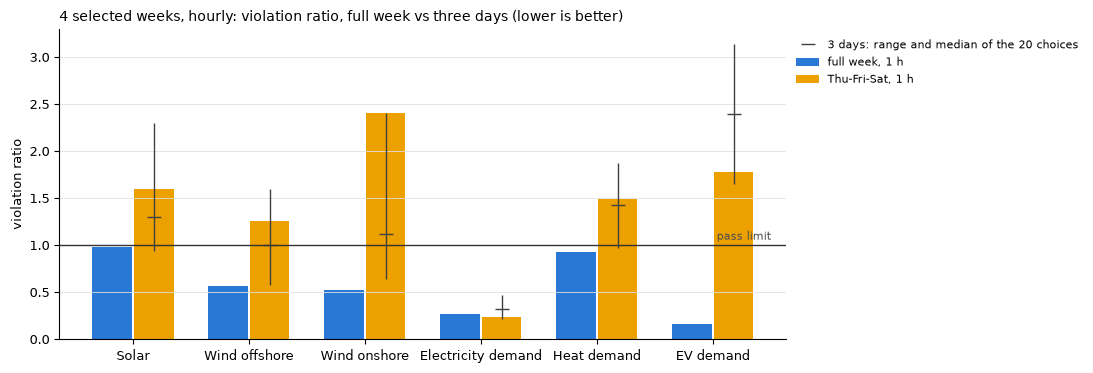

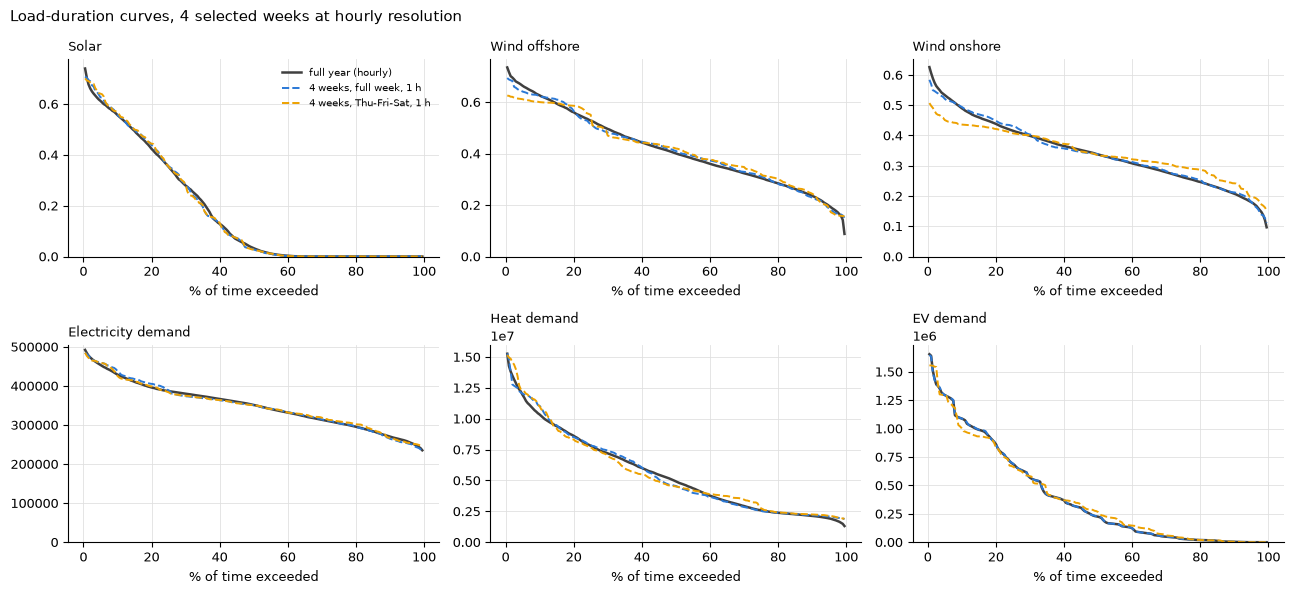

In [83]:
# 11.2 Figures: violation ratio per input and load-duration curves, full week vs Thu-Fri-Sat, hourly
COLOR_1H = {"full week, 1 h": "#2a78d6", "Thu-Fri-Sat, 1 h": "#eda100"}
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(TESTED))
for k, col in enumerate(COLOR_1H):
    ax.bar(x + (k - 0.5) * 0.36, table_1h.loc[TESTED, col], width=0.34, color=COLOR_1H[col], label=col)
# spread over the 20 day choices: thin line from best to worst, tick at the median
ax.vlines(x + 0.18, sens_1h[TESTED].min(), sens_1h[TESTED].max(), color="0.25", lw=1)
ax.plot(x + 0.18, sens_1h[TESTED].median(), "_", color="0.25", ms=10, label="3 days: range and median of the 20 choices")
ax.axhline(1, color="0.2", lw=1)
ax.text(len(TESTED) - 0.5, 1.03, "pass limit", ha="right", va="bottom", fontsize=8, color="0.3")
ax.set_xticks(x, TESTED)
ax.set_ylabel("violation ratio")
ax.set_title("4 selected weeks, hourly: violation ratio, full week vs three days (lower is better)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.flat, TESTED):
    full_c, sel_full = hourly_full[2][name]
    _, sel_days = hourly_days[2][name]
    ax.plot(Q, full_c, color="0.25", lw=1.8, label="full year (hourly)")
    ax.plot(Q, sel_full, color=COLOR_1H["full week, 1 h"], lw=1.4, ls="--", label="4 weeks, full week, 1 h")
    ax.plot(Q, sel_days, color=COLOR_1H["Thu-Fri-Sat, 1 h"], lw=1.4, ls="--", label="4 weeks, Thu-Fri-Sat, 1 h")
    ax.set_title(name, loc="left", fontsize=9.5)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("% of time exceeded")
axes.flat[0].legend(frameon=False, fontsize=7)
fig.suptitle("Load-duration curves, 4 selected weeks at hourly resolution", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

In [84]:
# 11.3 Summary: what the missing days cost at hourly resolution, next to the 3 h results of sections 9 and 10
c3 = "3 days (Thu-Fri-Sat)"
overview = pd.DataFrame({
    "full week, 1 h": hourly_full[0],
    "Thu-Fri-Sat, 1 h": hourly_days[0],
    "full week, 3 h": runs["4 weeks", "full week", "hourly"][best_start["4 weeks", "full week"]][0],
    "Thu-Fri-Sat, 3 h": runs["4 weeks", c3, "hourly"][best_start["4 weeks", c3]][0],
})
overview.loc["inputs passing"] = (overview.iloc[:len(TESTED)] <= 1).sum()
overview.loc["mean ratio"] = overview.iloc[:len(TESTED)].mean()
overview.loc["steps per week"] = [168, 72, 56, 24]
print("4 selected weeks, violation ratio against the hourly full year")
display(overview.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing", "steps per week"], :]))

f, d = overview["full week, 1 h"].iloc[:len(TESTED)], overview["Thu-Fri-Sat, 1 h"].iloc[:len(TESTED)]
worse = (d - f).sort_values(ascending=False)
print(f"hourly, full week -> Thu-Fri-Sat: inputs passing {int((f <= 1).sum())}/{len(TESTED)} -> {int((d <= 1).sum())}/{len(TESTED)}; "
      f"mean ratio {f.mean():.2f} -> {d.mean():.2f}")
print("largest increases:", ", ".join(f"{k} {f[k]:.2f} -> {d[k]:.2f}" for k in worse.index[:3]))
print(f"over all 20 day choices (hourly): inputs passing {int(ranking['inputs passing'].min())}-{int(ranking['inputs passing'].max())}, "
      f"mean ratio best {ranking['mean ratio'].min():.2f} ({ranking.index[0]}) / median {ranking['mean ratio'].median():.2f} / worst {ranking['mean ratio'].max():.2f}")

4 selected weeks, violation ratio against the hourly full year


,"full week, 1 h","Thu-Fri-Sat, 1 h","full week, 3 h","Thu-Fri-Sat, 3 h"
Solar,0.98,1.60,1.14,1.75
Wind offshore,0.57,1.25,0.57,1.28
Wind onshore,0.52,2.40,0.51,2.17
Electricity demand,0.27,0.24,0.31,0.31
Heat demand,0.92,1.49,0.97,1.55
EV demand,0.16,1.78,3.14,3.99
inputs passing,6,1,4,1
mean ratio,0.57,1.46,1.10,1.84
steps per week,168,72,56,24


hourly, full week -> Thu-Fri-Sat: inputs passing 6/6 -> 1/6; mean ratio 0.57 -> 1.46
largest increases: Wind onshore 0.52 -> 2.40, EV demand 0.16 -> 1.78, Wind offshore 0.57 -> 1.25
over all 20 day choices (hourly): inputs passing 1-4, mean ratio best 1.14 (Tue-Fri-Sun) / median 1.29 / worst 1.56


### 12. Three days every hour or the full week every 3 hours? (4 selected weeks)

Two ways to cut the 168 hours of each week to a similar model size:

| Configuration | Hours kept per week | Steps per week | `CHRONOHOUR` |
|---|---|---|---|
| 3 days, every hour | 2 weekdays + 1 weekend day, T at 1 h | 72 | 2.33 h |
| full week, every 3 hours | all 7 days, every 3rd hour | 56 | 3 h |

The first keeps the hour-to-hour shape but loses 4 days of the week; the second keeps every day but loses the hours in between.
Both are tested on the 4 selected weeks (section 5) against the **hourly full year**, with the same pass test as before. Each configuration is shown
- in its **base form**: Thu-Fri-Sat (the days in the current scenarios) and starting hour T001 (T001, T004, ..., as in the scenarios);
- at its **best**: the best of the 20 day choices (section 11) and the best of the 3 starting hours (section 9).

The full week every hour is the reference (best case). Note that 3 days every hour has 29 % more steps than the full week every 3 hours.

In [85]:
# 12.1 Violation ratios: 3 days every hour vs full week every 3 hours (4 selected weeks, reference: hourly full year)
best_days = ranking.index[0]                                            # best day choice at 1 h (section 11)
fw3 = runs["4 weeks", "full week", "hourly"]                            # full week at 3 h, one entry per starting hour (section 10)
bp3 = best_start["4 weeks", "full week"]
days_best = hourly_config(tuple(best_days.split("-")))

CONFIG_12 = {
    "3 days 1 h (Thu-Fri-Sat)": (hourly_days, 72),
    f"3 days 1 h (best: {best_days})": (days_best, 72),
    "full week 3 h (T001, T004, ...)": (fw3[0], 56),
    f"full week 3 h (best: {PHASES[bp3]})": (fw3[bp3], 56),
    "full week 1 h (reference)": (hourly_full, 168),
}
table_12 = pd.DataFrame({name: res[0] for name, (res, _) in CONFIG_12.items()})
table_12.loc["inputs passing"] = (table_12.iloc[:len(TESTED)] <= 1).sum()
table_12.loc["mean ratio"] = table_12.iloc[:len(TESTED)].mean()
table_12.loc["steps per week"] = [n for _, n in CONFIG_12.values()]
print("Violation ratio against the hourly full year (1 or below = pass)")
display(table_12.style.format("{:.2f}").format("{:.0f}", subset=pd.IndexSlice[["inputs passing", "steps per week"], :]))

err_12 = pd.concat({"3 days 1 h (Thu-Fri-Sat)": hourly_days[1], "full week 3 h (T001, T004, ...)": fw3[0][1]}, axis=1)
err_12 = err_12.loc[:, [(k, c) for k in err_12.columns.levels[0] for c in ["LDC error", "P5 error", "P95 error"]]]
print("Errors of the base forms against the hourly full year")
display(err_12.style.format("{:+.1%}"))

Violation ratio against the hourly full year (1 or below = pass)


,3 days 1 h (Thu-Fri-Sat),3 days 1 h (best: Tue-Fri-Sun),"full week 3 h (T001, T004, ...)","full week 3 h (best: T002, T005, ...)",full week 1 h (reference)
Solar,1.60,1.66,1.54,1.14,0.98
Wind offshore,1.25,0.94,0.61,0.57,0.57
Wind onshore,2.40,0.86,0.54,0.51,0.52
Electricity demand,0.24,0.28,0.30,0.31,0.27
Heat demand,1.49,0.97,0.94,0.97,0.92
EV demand,1.78,2.53,3.14,3.14,0.16
inputs passing,1,4,4,4,6
mean ratio,1.46,1.21,1.18,1.10,0.57
steps per week,72,72,56,56,168


Errors of the base forms against the hourly full year


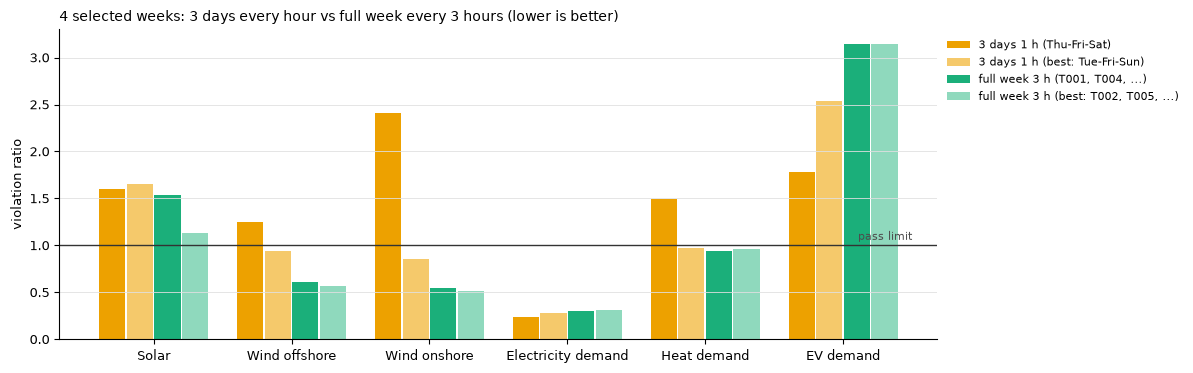

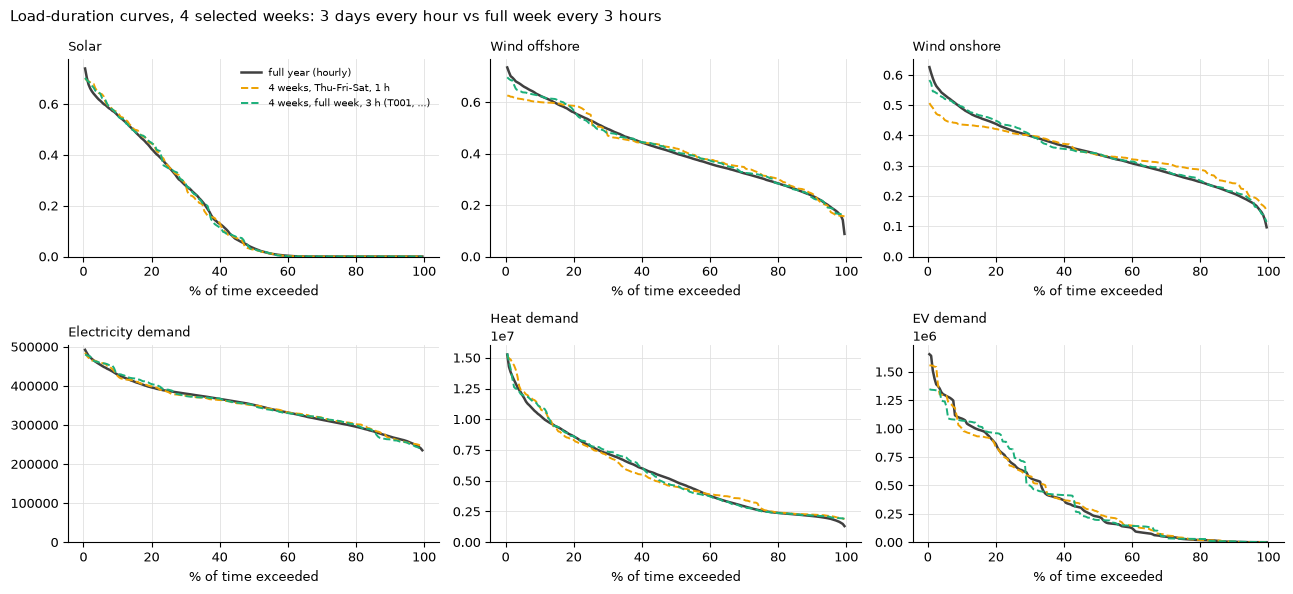

In [86]:
# 12.2 Figures: violation ratio per input and load-duration curves of the two base forms
COLOR_12 = {"3 days 1 h (Thu-Fri-Sat)": "#eda100", f"3 days 1 h (best: {best_days})": "#f5c96b",
            "full week 3 h (T001, T004, ...)": "#1baf7a", f"full week 3 h (best: {PHASES[bp3]})": "#8fd9bd"}
fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(len(TESTED))
width = 0.8 / len(COLOR_12)
for k, col in enumerate(COLOR_12):
    ax.bar(x + (k - (len(COLOR_12) - 1) / 2) * width, table_12.loc[TESTED, col], width=width * 0.95, color=COLOR_12[col], label=col)
ax.axhline(1, color="0.2", lw=1)
ax.text(len(TESTED) - 0.5, 1.03, "pass limit", ha="right", va="bottom", fontsize=8, color="0.3")
ax.set_xticks(x, TESTED)
ax.set_ylabel("violation ratio")
ax.set_title("4 selected weeks: 3 days every hour vs full week every 3 hours (lower is better)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.flat, TESTED):
    full_c, sel_days = hourly_days[2][name]
    _, sel_3h = fw3[0][2][name]
    ax.plot(Q, full_c, color="0.25", lw=1.8, label="full year (hourly)")
    ax.plot(Q, sel_days, color=COLOR_12["3 days 1 h (Thu-Fri-Sat)"], lw=1.4, ls="--", label="4 weeks, Thu-Fri-Sat, 1 h")
    ax.plot(Q, sel_3h, color=COLOR_12["full week 3 h (T001, T004, ...)"], lw=1.4, ls="--", label="4 weeks, full week, 3 h (T001, ...)")
    ax.set_title(name, loc="left", fontsize=9.5)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("% of time exceeded")
axes.flat[0].legend(frameon=False, fontsize=7)
fig.suptitle("Load-duration curves, 4 selected weeks: 3 days every hour vs full week every 3 hours", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

In [87]:
# 12.3 Summary
cols = list(CONFIG_12)
for a, b in [(cols[0], cols[2]), (cols[1], cols[3])]:
    ra, rb = table_12[a].iloc[:len(TESTED)], table_12[b].iloc[:len(TESTED)]
    better = [k for k in TESTED if ra[k] < rb[k]]
    print(f"{a}  vs  {b}:")
    print(f"   inputs passing {int((ra <= 1).sum())}/{len(TESTED)} vs {int((rb <= 1).sum())}/{len(TESTED)}; mean ratio {ra.mean():.2f} vs {rb.mean():.2f}")
    print(f"   3 days every hour is better for: {', '.join(better) or 'none'}; full week every 3 h is better for: "
          f"{', '.join(k for k in TESTED if k not in better) or 'none'}")

3 days 1 h (Thu-Fri-Sat)  vs  full week 3 h (T001, T004, ...):
   inputs passing 1/6 vs 4/6; mean ratio 1.46 vs 1.18
   3 days every hour is better for: Electricity demand, EV demand; full week every 3 h is better for: Solar, Wind offshore, Wind onshore, Heat demand
3 days 1 h (best: Tue-Fri-Sun)  vs  full week 3 h (best: T002, T005, ...):
   inputs passing 4/6 vs 4/6; mean ratio 1.21 vs 1.10
   3 days every hour is better for: Electricity demand, EV demand; full week every 3 h is better for: Solar, Wind offshore, Wind onshore, Heat demand
